# Praktikum Clustering dengan Pendekatan CRISP-DM

# IDENTITAS

Nama: Shafira Nor Putri Wawan
NIM: 09020625077

# BAB 1 Pengantar CRISP-DM untuk Clustering

CRISP-DM adalah kerangka kerja proyek data mining yang terdiri atas enam tahap. Tahap-tahapnya beersifat iteratif. Temuan EDA dapat mengubah pemahaman masalah, hasil evaluasi dapat mengharuskan pemodelan ulang rekomendasi harus kembali diperiksa terhadap tujuan bisnis.

## Konsep penting

- Clustering adalah metode unsupervised learning: tidak membutuhkan label target yang sudah diketahui.
- Cluster bukan otomatis kategori benar secara mutlak. Cluster adalah pola yang dihasilkan dari fitur, jarak, algoritma, dan paramter tertentu.
- Scaling penting karena algoritma berbasis jarak dapat didominasi fitur dengan rentang nilai besar.
- Skor metrik internal perlu dilengkapi interpretasi bisnis. Skor terbaik tidak selalu menghasilkan segmentasi paling berguna.
- CustomesID adalah pengenal, bukan fitur perilaku. Jangan masukkan CustomerID sebagai variabel clustering.

In [2]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

# BAB 2 Dataset dan Persiapan Lingkungan

## 2.2 Mengunduh dan membaca data

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from zipfile import ZipFile
import requests, io

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
response = requests.get(url, timeout=60)
response.raise_for_status()

with ZipFile(io.BytesIO(response.content)) as z:
  files = z.namelist()
  print("Isi ZIP:", files)
  excel_file = next(name for name in files if name.lower().endswith((".xlsx", ".xls")))
  with z.open(excel_file) as f:
    df = pd.read_excel(f)

print(df.shape)
df.head()

Isi ZIP: ['Online Retail.xlsx']
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2.3 Menyamakan nama kolom

In [4]:
df.columns = [c.strip() for c in df.columns]
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Tugas Awal

1. Jumlah baris: 541909
2. Jumlah kolom: 8

3. Identifikasi Kolom numerik:
- Quantity
- Unitprice
- Customer ID

Kategorikal:
- Description
- Country

Tanggal:
- Invoice date

Pengenal:
- InvoiceNo
- CustomerID
- StockCode

4. Analisis penggunaan CustomerID yang tidak dipakai diawal sebagai fitur clustering:

Karena dataset merupakan data transaksional per item/invoice, bukan ringkasan per pelanggan. Satu cutomerID dapat tercatat berulang-ulang di banyak transaksi berbeda. Jika digunakan model akan mengclustering pada tingka baris transaksinya bukan dikelompokkan berdasarkan profil pelanggan.

- versi awal: Online Ritel Dataset (v1.0)
- Tanggal di unduh: 30 0ktober 2026

# Tahapan Praktim

| Praktikum | Tahap | Hasil yang Dihasilkan |
|---|---|---|
| 1 | Business Understanding | Rumusan masalah bisnis (toko online belum punya pengelompokan pelanggan berdasarkan perilaku belanja), tujuan analitik, 3 pertanyaan analitik, kriteria sukses teknis dan bisnis, serta unit analisis berupa pelanggan (bukan transaksi). |
| 2 | Rencana Analisis | Rancangan kerja: periode data 1 Des 2010 – 9 Des 2011, tanggal acuan Recency 10 Des 2011, fitur RFM (Recency, Frequency, Monetary), dan metrik evaluasi (Silhouette dan Davies-Bouldin). |
| 3 | Data Understanding | Pemahaman struktur data (541.909 baris, 8 kolom, 1 baris = 1 item dalam invoice), kamus data, dan temuan CustomerID kosong sebanyak 24,93%. |
| 4 | EDA Kualitas Data | Laporan kualitas data: CustomerID kosong 135.080, duplikat 5.268, invoice pembatalan (awalan C) 9.288, Quantity ≤ 0 sebanyak 10.624, UnitPrice ≤ 0 sebanyak 2.517, disertai keputusan dan risikonya. |
| 5 | EDA Transaksi dan Pola Bisnis | Visualisasi dan dua pola bisnis: penjualan memuncak akhir tahun (±1,16 juta pada Nov 2011) dan pasar didominasi United Kingdom. Hasil ini mendukung penggunaan log1p dan tidak memakai Country sebagai fitur. |
| 6 | Data Preparation | Data bersih 392.692 baris (dari 541.909) dengan 4.338 pelanggan, tabel log pembersihan, dan data mentah yang tetap disimpan terpisah. |
| 7 | Fitur RFM | Tabel RFM satu baris per pelanggan (4.338 × 3). Frequency dan Monetary ditransformasi log1p, sehingga fitur final adalah Recency, Frequency_log, dan Monetary_log. |
| 8 | Modeling K-Means | Model K-Means dengan perbandingan k = 2–7 (elbow dan silhouette). k = 3 terbaik: silhouette 0,416 dan Davies-Bouldin 0,825. |
| 9 | Modeling K-Medoids | Model pembanding berbasis medoid. Skor mirip K-Means (silhouette 0,414), tetapi lebih lambat dan tidak memberi keunggulan nyata. |
| 10 | Modeling Hierarchical | Model Ward dan Complete beserta dendrogram. Skor mirip, tetapi optimal hanya pada 2 cluster. |
| 11 | Modeling DBSCAN | Uji 5 nilai eps. eps kecil menghasilkan silhouette 0,105 dan noise 6,52%, sedangkan eps besar hanya membentuk 1 cluster, sehingga tidak cocok untuk data ini. |
| 12 | Evaluasi Model | Tabel perbandingan semua algoritma. K-Means (k = 3) terbaik: skor tertinggi, tanpa noise, dan mudah dijelaskan. |
| 13 | Evaluasi Iteratif dan Profil Cluster | Profil 3 segmen, ditambah memo evaluasi yang merekomendasikan K-Means k = 3. |
| 14 | Deployment dan Komunikasi Hasil | Laporan akhir 8 bagian: rekomendasi per segmen, indikator pemantauan, risiko, dan reproducibility (seed 42, versi paket). |

## Profil Segmen Pelanggan (K-Means, k = 3)

| Cluster | Segmen | Pelanggan | Recency (median) | Frequency (median) | Monetary (median) | Rekomendasi |
|---|---|---|---|---|---|---|
| 2 | Aktif & Bernilai Tinggi | 1.320 (30,43%) | 18 hari | 7 | £2.570,50 | Program loyalitas dan penawaran eksklusif |
| 0 | Aktif Belanja Menengah | 2.038 (46,98%) | 46 hari | 2 | £508,80 | Rekomendasi produk dan promosi pembelian ulang |
| 1 | Lama Tidak Aktif | 980 (22,59%) | 253 hari | 1 | £290,46 | Kampanye reaktivasi dengan anggaran terukur |

## Kesimpulan Singkat
Dari 541.909 transaksi mentah, data dibersihkan menjadi 392.692 baris dengan 4.338 pelanggan, lalu diringkas menjadi fitur RFM. Empat algoritma dibandingkan, dan **K-Means dengan 3 cluster** dipilih karena skor terbaik (silhouette 0,4157; Davies-Bouldin 0,8249), tanpa noise, dan menghasilkan segmen yang jelas serta bisa ditindaklanjuti. Segmen bernilai tinggi menyumbang sekitar 81,57% pendapatan.

# Praktikum 1 - Business Understanding

# Tujuan

- Membedakkan masalah bisnis dengan masalah analitik.
- Menentukan tujuan segmentasi pelanggan yang dapat ditindaklanjuti.
- Menyusun pertanyaan analitik dan asumsi awal

## Skenario

Sebuah toko online memiliki catatan transaksi historis. Tim pemasaran ingin memahami perbedaan pola pembelian pelanggan agar komunikasi pemasaran, program loyalitas, dan promosi dapat dirancang lebih relevan. Belum tersedia label pelanggan seperti 'loyal', 'baru', atau 'berisiko'.

## Langkah Kerja

### 1 Masalah Bisnis tanpa menyebut algoritma

Toko online ini memiliki catatan historis, tetapi belum tersedia  pengelompokan pelanggan berdasarkan karakteristik perilaku belanja seperti pelanggan loyal, baru, atau berisiko. Akibatnya, manajemen sulit memahami perbedaan pola pembelian pelanggan secara objektif dan memperlakukan pelanggan dengan cara yang sama. Hal ini membuat komunikasi pemasaran, program loyalitas, dan promosi sulit dirancang supaya tepat sasaran setiap kelompok pelanggan

### 2 Pengguna hasi analisis

Pengguna merupakan bagian manajemen pemasaran yang menentukan strategi promosi, program loyalitas, dan alokasi penganggaran per kelompok pelanggan. Pendukung pengguna adalah tim CRM, yang mengelopokkan profil pelanggan untuk menyusun strategi pendekatan komunikasi yang sesuai sasaran.


### 3 Tujuann Analitik

Membentuk kelompok pelanggan berdasarkan perilaku transaksi, seberapa baru mereka terakhir berbelanja, seberapa seering berbelanja, dan seberapa besar nilai belanjanya. Pengelompokan dilakukan pada tingkat pelanggan bukan di bagian baris transaksinya tanpa label yang sudah ada, agar setiap kelompok bisa diberi profil dan dimanfaatkan tim pemasaran.

### 4 Pertanyaan Analitik (3 Pertanyaan)

1. Apakah terdapat kelompok pelanggan dengan frekuensi pembelian dan nilai belanja yang berbeda?
2. Kelompok mana yang berisi pelanggan yang sudah lama tidak berbelanja dan berpotensi berhenti membeli (berisiko)?
3. Kelompok mana yang berisi pelanggan dengan frekuensi dan nilai belanja tinggi sehingga layak mendapat program loyalitas?


### 5 Kriteria kerberhasilan

Secara teknis:
- Kelompok yang terbentuk dapat dievaluasi dengan metrik internal dan menunjukkan pemisahan antarkelompok yang jelas.
- Tidak ada kelompok yang terbentuk hanya dari anomali data, misal satu atau dua pelanggan dengan nilai belanja ekstrem.
- Hasil cukup stabil, artinya pembelian kelompok tidak berubah drastis karena analisis diulang dengan pengaturan awal yang berbeda.

Secara bisnis:
- Setiap kelompok memiliki profil yang dapat dijelaskan dengan bahasa sederhana misalnya, "Pelanggan setia bernilai tinggi" atau "Pelanggan lama yang tidak aktif"
- Setiap kelompok berpotensi ditidaklanjuti dengan strategi yang jelas, seperti promosi khusus, program loyalitas, atau kampanye aktivasi ulang.
- Manajer pemasaran dapat memahami dan memakai hasilnya tanpa perlu latar belakang teknis.

## Lembar Kerja

### Masalah Bisnis

Tim pemasara belum bisa memahami perbedaan pola pembelian pelanggan karena belum dikelopokkan berdasarkan perilaku belanja, sehingga komunikasi pemasaran, program loyalitas, dan promosi belum tepat sasaran.

### Tujuan Analitik

Menemukan pola perilaku belanja pelanggan seperti seberapa baru, seberapa sering, dan seberapa besar nilai belanja untuk membentuk kelompok pelanggan yang dapat diberi profil.

### Unit Analisis

Pelanggan (Satu baris mewakili satu CustomerID), bukan baris transaksi. Data transaksi diringkas dulu menjadi fitur / pelanggan.

### Pertanyaan Analitik

1. Apakah terdapat kelompok pelanggan dengan frekuensi pembelian dan nilai belanja yang berbeda?
2. Kelompok mana yang berisi pelanggan yang sudah lama tidak berbelanja dan berpotensi berhenti membeli?
3. Kelompok mana yang berisi pelanggan dengan frekuensi dan nilai belanja tinggi sehingga layak mendapa program loyalitas?

### Kriteria Teknis

Kelompok dapat dievaluasi melalui metrik internal dengan pemisahan yang jelas, tidak didominasi data anomali, dan hasilnya akan stabil saat dilakukan analisis ulang dengan pengaturan awal berbeda.

### Kriteria Bisnis

Setiap kelompok memiliki profil yang dapat dijelasakan dengan bahasa sederhana dan berpotensi ditindaklanjuti dengan strategi yang jelas, serta manajer pemasaran dapat memahami tanpa latar belakang teknis.

### Resiko atau Asumsi

Risiko yang dihadapi data historis menjadi tidak selalu dapat mewakili perilaku masa depan, CustomerID yang kosong tidak bisa dilakukan profil, pelanggan dengan nilai belanja ekstrem dapat dikelompokan semu.

Asumsinya perilaku transaksi di masa lalu cukup menggambarkan kebiasaan belanja pelanggan, dan satu CustomerID dapat mewakili satu pelanggan yang sama.

## Pertanyaan Refleksi

1. K-means hanyalah alat, bukan masalah. Rumusan masalah dapat menjabarkan kesulitan keputusan apa yang tengah dihadapi oleh organisasi dan hasil apa yang dibutuhkan. Jika tujuannya hanya penggunaan K-means akan tidak jelas siapa pengguna hasil analisisnya, yang ingin diketahui, unit analisis dan ukuran keberhasilannya. Akibatnya, analisis bisa berjalan secara teknis tapi hasilnya akan bias bagi tim pemasaran. Pemilihan algoritma sebaiknya mengikuti masalah, K-means dipilih setelah tujuan, data, dan kriteria keberhasilan jelas, dan bisa diganti metode lain jika terasa kurang cocok

2. Jumlah cluster perlu dilakukan penentuan oleh struktur data dan kebutuhan bisnis. Angka tiga yang dipaksakan bisa menyatukan pelanggan yang berbeda atau memecah kelompok yang sebenarnya satu. Jumlah yang tepat perlu diuji dengan metrik internal, dicek kestabilannya, dan diniali apakah tiap kelompok bisa dijelaskan dan ditindaklanjuti.

3. Clustering tidak punya label benar sebagai pembanding, sehingga cluster bisa terbentuk dari anomali atau data yang tidak mewakili perilaku masa depan. Jika langsung dipakai otomatis, pelanggan bisa salah sasaran, anggaran pemasaran terbuang, dan keputusan sulit dipertanggungjawabkan. Hasilnya perlu divalidasi pihak bisnis dan diuji kecil-kecilan dulu.

## Praktikum 2 - Menetapkan Rencana Analisi

### Langkah Kerja

6. Data yang dianalisis adalah transaksi valid dari 1 desember 2010 - 9 Desember 2011, berdasarkan nilai min dan max pada InvoiceDate 1 Desember 2010 08:26 - 9 Desember 2011 12:50. Acuan tanggal digunakan menghitung Recency adalah 10 Desember 2011, yaitu seharu setelah transaksi terakhir. Seleruh rentang digunakan karena mencakup satu siklus tahunan penuh, sehingga frequency dan monetry tidak bias oleh musim tertentu.

7. Satu baris pada tebal terakhir mewakili satu pelanggan (satu customer id), bukan satu baris item transaksi. CustomerID hanya sebagai pengenal dan tidak dimasukkan ke fitur clustering.

8. Fitur awal (RFM)

- Recency: Jumlah hari antara tanggal acuan dan tanggal transaksi terakhir pelanggan (nilai yang kecil berarti lebih baru).
- Frequency: Jumlah InvoiceNo unik per pelanggan
- Monetary: Jumlah LineValue (Quantity x UnitPrice) / pelanggan.


9. Metrik evaluasi

- Silhoutte score: makin tinggi makin baik (kelompok rapat dan terpisah).
- Davies Bouldin Index: makin rendah makin baik.
- Profil cluster: jumlah dan persentase pelanggan serta median dan rata-rata Recency, frequency, monetry asli tiap cluster, lalu dinilai apakah dapat dijelaskan dan ditindaklanjuti.
- Jumlah cluster dibandingkan pada k=2 sampai 7, skor tertinggi tidak otomatis dipilih tanpa tinjauan interpretasi bisnis.

## Praktikum 3 - Data understanding

## Tujuan

- Memahami struktur dataset dan arti kolom.
- Mengenali rentang waktu, jumlah pelanggan, dan unit observasi

## Kode Praktik

In [5]:
print("ukuran data:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))
df.info()

display(df.describe(include="all").T)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Tanggal minimum:", df["InvoiceDate"].min())
print("Tanggal maksimum:", df["InvoiceDate"].max())

for col in ["invoiceNo", "StockCode", "CustomerId", "Country"]:
  if col in df.columns:
    print(col, ":", df[col].nunique(dropna=True))

ukuran data: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tanggal minimum: 2010-12-01 08:26:00
Tanggal maksimum: 2011-12-09 12:50:00
StockCode : 4070
Country : 38


## Interpretasi

1. Satu baris mewakili satu item produk dalam satu invoice. satu invoice bisa terdiri dari banyak baris, dan satu pelanggan bisa mewakili bayak invoice. Jadi jumlah baris (541.909) jauh lebih besar daripada jumlah invoice dan jumlah pelanggan.

2. Kolom yang dipakai membuat fitur perilaku pelanggan
- CustomerID sebagai kunci untuk agregasi data per pelanggan (bukan fitur)
- InvoiceDate untuk Recency
- InvoiceNo untuk Frequency (jumlah invoice unik)
- Quantity dan UnitPrice untuk monetry lewat LineValue (Quantity x UnitPrice)
- Country opsional sebagai konteks profil. StockCode dan Description tidak dipakai untuk RFM.

3. Konsekuensi CustomerID yang kosong terhadap segmentasi pelanggan

Baris tanpa customerID tidak bisa diagregasi menjadi satu pelanggan, sehingga harus dikelaurkan dari analisi pelanggan. Jumlahnya besar, sekitarnya 135.080 baris* atau 24,93% dari seluruh data. Akibatnya, segementasi hanya mewakili pelanggan yang teridentifikasi, dan total belanja toko sebenarnya lebih besar daripada yang tercakup analisis. Ini perlu di catat sebagai keterbatasan

4. Memeriksa format InvoiceDate analsis waktu

Recency dihitug dari selisih taggal, dan tren per bulan butuh pengelompokan berdasarkan waktu. Keduanya hanya benar jika InvoiceDate bertipe datetime. Jika penggunana berupa tesk, pengurutan bisa salah dan selisish hari tidak dapat dihitung. Parameter errors="coerce" mengubah tanggal yang gagal terbaca menjadi NaT, jadi jumlah NaT perlu dicek (df["InvoiceDate"].isna().sum()) agar tidak ada data yang hilang diam-diam.

## Tugas membuat kamus data dengan kolom

In [6]:
import pandas as pd

# kamus data dari tabel Online Retail
data = {
    "Nama Fitur": [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "InvoiceDate",
        "UnitPrice",
        "CustomerID",
        "Country"
    ],
    "Tipe Data": [
        "object(teks)",
        "object(teks)",
        "object (teks)",
        "int64",
        "datetime64[ns]",
        "float64",
        "float64",
        "object (teks)"
    ],
    "Makna": [
        "Nomor invoice: Satu invoice bisa berisi banyak baris item. Awalan \"C\" menandakan pembatalan",
        "Kode unik produk",
        "Nama atau deskripsi produk",
        "Jumlah unit produk pada satu baris item",
        "Tanggal dan jam transaksi",
        "Harga satuan produk (GBP, menurut dokumentasi UCI)",
        "Pengenal unik pelanggan",
        "Negara tempat pelanggan berada"
    ],
    "Contoh Nilai": [
        "536365",
        "85123A",
        "WHITE HANGING HEART T-LIGHT HOLDER",
        "6",
        "2010-12-01 8:26:00",
        "2.55",
        "17850.0",
        "United Kingdom"
    ],
    "Potensi Masalah Kualitas": [
        "25.900 nilai unik, jadi rata-rata sekitar 21 baris per invoice. Invoice berawalan \"C\" bercampur dengan pembelian.",
        "4.070 nilai unik. Sebagian berhuruf, dan kemungkinan ada kode non-produk (misalnya POST, D, M) yang perlu dilakukan pengecekan.",
        "1.454 baris kosong (0,27%). Ada 4.223 deskripsi unik untuk 4.070 kode, artinya satu kode bisa punya lebih dari satu penulisan.",
        "Minimum -80.995 dan maksimum 80.995 (retur/pembatalan dan nilai ekstrem). Median 3 tetapi rata-rata 9,55 dengan std 218,08, tanda distribusi sangat menceng.",
        "Rentang 1 Desember 2010 sampai 9 Desember 2011. Tidak ada nilai kosong (count 541.909), tetapi tetap cek NaT setelah konversi.",
        "Minimum -11.062,06 (tidak wajar untuk harga) dan maksimum 38.970. Median 2,08 jauh di bawah rata-rata 4,61 dengan std 98,76, jadi sangat menceng.",
        "135.080 baris kosong (24,93%); terisi 406.829 dari 541.909). Bertipe float karena ada NaN, padahal berfungsi sebagai ID.",
        "38 negara, tetapi United Kingdom mendominasi dengan 495.478 baris (91,43%)."
    ],
    "Kemungkinan Penggunaan": [
        "Frequency (invoice unik per pelanggan), penanda pembatalan",
        "Analisis produk pada EDA, bukan fitur clustering",
        "Analisis produk pada EDA, bukan fitur clustering",
        "Monetary lewat LineValue (Quantity x UnitPrice)",
        "Recency, tren transaksi per bulan",
        "Monetary lewat LineValue",
        "Kunci agregasi per pelanggan (bukan fitur clustering)",
        "Konteks profil cluster dan EDA"
    ]
}

# Membuat DataFrame
df_kamus_data = pd.DataFrame(data)

# Mengatur agar tampilan tabel lebih rapi di Jupyter / Colab
display(
    df_kamus_data.style.set_properties(
        **{'text-align': 'left', 'vertical-align': 'top'}
    ).set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('text-align', 'center'),
                ('background-color', '#d9ead3'),
                ('font-weight', 'bold'),
                ('color', 'black')
            ]
        }
    ])
)

,Nama Fitur,Tipe Data,Makna,Contoh Nilai,Potensi Masalah Kualitas,Kemungkinan Penggunaan
0,InvoiceNo,object(teks),"Nomor invoice: Satu invoice bisa berisi banyak baris item. Awalan ""C"" menandakan pembatalan",536365,"25.900 nilai unik, jadi rata-rata sekitar 21 baris per invoice. Invoice berawalan ""C"" bercampur dengan pembelian.","Frequency (invoice unik per pelanggan), penanda pembatalan"
1,StockCode,object(teks),Kode unik produk,85123A,"4.070 nilai unik. Sebagian berhuruf, dan kemungkinan ada kode non-produk (misalnya POST, D, M) yang perlu dilakukan pengecekan.","Analisis produk pada EDA, bukan fitur clustering"
2,Description,object (teks),Nama atau deskripsi produk,WHITE HANGING HEART T-LIGHT HOLDER,"1.454 baris kosong (0,27%). Ada 4.223 deskripsi unik untuk 4.070 kode, artinya satu kode bisa punya lebih dari satu penulisan.","Analisis produk pada EDA, bukan fitur clustering"
3,Quantity,int64,Jumlah unit produk pada satu baris item,6,"Minimum -80.995 dan maksimum 80.995 (retur/pembatalan dan nilai ekstrem). Median 3 tetapi rata-rata 9,55 dengan std 218,08, tanda distribusi sangat menceng.",Monetary lewat LineValue (Quantity x UnitPrice)
4,InvoiceDate,datetime64[ns],Tanggal dan jam transaksi,2010-12-01 8:26:00,"Rentang 1 Desember 2010 sampai 9 Desember 2011. Tidak ada nilai kosong (count 541.909), tetapi tetap cek NaT setelah konversi.","Recency, tren transaksi per bulan"
5,UnitPrice,float64,"Harga satuan produk (GBP, menurut dokumentasi UCI)",2.55,"Minimum -11.062,06 (tidak wajar untuk harga) dan maksimum 38.970. Median 2,08 jauh di bawah rata-rata 4,61 dengan std 98,76, jadi sangat menceng.",Monetary lewat LineValue
6,CustomerID,float64,Pengenal unik pelanggan,17850.0,"135.080 baris kosong (24,93%); terisi 406.829 dari 541.909). Bertipe float karena ada NaN, padahal berfungsi sebagai ID.",Kunci agregasi per pelanggan (bukan fitur clustering)
7,Country,object (teks),Negara tempat pelanggan berada,United Kingdom,"38 negara, tetapi United Kingdom mendominasi dengan 495.478 baris (91,43%).",Konteks profil cluster dan EDA


https://docs.google.com/spreadsheets/d/10bThd-wfWWWMM2Lk1FF1PTE4qi8BtsDfJL6_AlKuA10/edit?usp=sharing


## Praktikum 4 EDA Kualitas Data

## Tujuan

- Mengukur mising values, duplikasi, dan nilai tidak wajar.
- Membedakkan anomali data dengan kejadian bisnis yang mungkin valid

## Kode Praktik

In [7]:
# Missing values
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
quality = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
display(quality)

# Duplikasi baris
print("Jumlah baris duplikat:", df.duplicated().sum())

# Nilai dasar yang perlu diperiksa
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())

print("InvoiceNo diawali C:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Distribusi numerik
display(df[["Quantity", "UnitPrice"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T)



,missing_count,missing_pct
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


Jumlah baris duplikat: 5268
Quantity <= 0: 10624
UnitPrice <= 0: 2517
InvoiceNo diawali C: 9288


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


## Visualisasi Kualitas Data

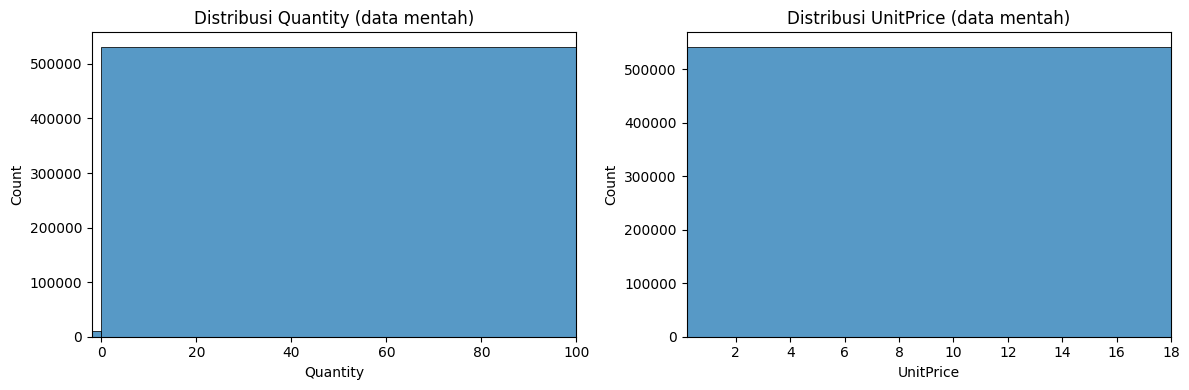

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Quantity"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("Distribusi Quantity (data mentah)")
axes[0].set_xlim(df["Quantity"].quantile(.01),
                 df["Quantity"].quantile(.99))

sns.histplot(df["UnitPrice"].dropna(), bins=50, ax=axes[1])
axes[1].set_title("Distribusi UnitPrice (data mentah)")
axes[1].set_xlim(df["UnitPrice"].quantile(.01),
                 df["UnitPrice"].quantile(.99))
plt.tight_layout()
plt.show()


## Panduan Keputusan

### 1 CustomerID kosong

- 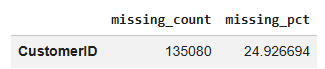
- **Temuan:** Terdapat 135.080 baris data yang memiliki nilai CustomerID kosong, atau mencakup sekitar 24,93% dari total keseluruhan data transaksi.
- **Tindakan:** keluarkan dari analisis pelanggan yang memerlukan identitas pelanggan; jangan otomatis hapus dari seluruh EDA
- **Alasan:** Segmentasi dilalukan di tingkat pelanggan, sehingga tiap transaksi harup dapat dihubungkan dengan satu CustomerId tidak dapat diagregasi Recency, Frequency dan Monetry per pelanggan, akibatnya tidak dapat diprofilkan. Namun, baris ini tetap memuat informasi penjualan yang valid, seperti produk, jumlah, harga, tanggal dan negara, sehingga dipertahankan untuk EDA, yang bisa digunakan sebagai analisis tren penjualan bulanan, produk terlaris dan penjualan antarnegara misalnya.



### 2 InvoiceNo diawali C

- 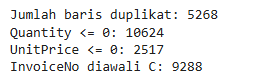
- **Temuan:** Terdapat 9.288 baris transaksi sekitar 1,71% dari total data dengan nomor InvoiceNo yang diawali huruf 'C'
- **Tindakan:** Periksa sebagai indikasi pembatalan; pastikan definisi sesuai sumber data.
- **Aturan identifikasi pembatalan:** Transaksi dianggap pembatalan jika nilai InvoiceNo, setelah diubah menjadi teks diawali huruf C. Aturan ini mengikuti dokumentasi sumber data UCI yang menyebutka bahwa InvoiceNo berawalan C menandakan pembatalan. total ada 9.288 baris yang memenuhi aturan ini, dan baris tersebut dikelaurkan dari baseline penjualan positif.

### 3 Quantity <=0

- 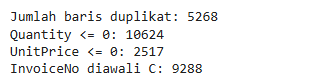
- **Temuan:** Terdapat 10.624 baris sekitar 1,96% data dengan nilai Quantity <= 0, mencakup nilai nol serta nilai negatif ekstrem, misalnya diakibatkan oleh pembatalan atau pencatatan koreksi stok.
- **Tindakan:** Periksa apakah retur atau pembatalan; jangan otomatis dianggap kesalahan.
- **Dampak terhadap nilai penjualan bersih:** Jika barisa ini dikeluarkan, monetary menjadi penjualan kotor karena retur dan pembatalan tidak dikurangkan, sehingga bisa lebih tinggi dari penjualan bersih sebenarnya. Jika dipertahankan monetary menggambarkan penjualan bersih, tetap pelanggan dengan banyak retur bisa bernilai kecil atau negatif

### 4 UnitPrice <=0

- 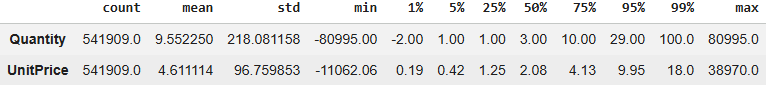
- **Temuan:** Terdapat 2.517 baris sekitar 0,46% dari total data dengan UnitPrice <=0 nilai minimumnya -1106206
- **Tindakan:** Periksa kemungkinan pencatatan khusus atau data tidak valid
- **Jumlah, aturan penanganan** Total 2517 baris ini dikeluarkan dari baseline pembelian karena LineValue (quantity x unitprice) menjadi nol atau negatif akibatnya tidak menggambarkan nilai belanja pelanggan. Harga negatif tidak wajar sebagai harga produk dan kemungkinan merupakan penyesuaian atau data tidak valid.

### 5 Duplikasi

- 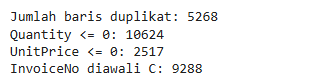
- **Temuan:** Terdapat 5268 baris sekitar 0,97% dari total data yang duplikat identik pada seluruh kolom.
- **Tindakan:** Periksa apakah duplikasi identik atau baris item sah.
- **Apakah dihapus?** ya, pada baseline cleaning baris duplikat identik dihapus
- **Alasan:** Baris yang serupa pada semua kolom termasuk waktu transaksi, kecil kemungkinan adalah transaksi berbeda, sehingga lebih mungkin duplikasi pencatatan. Jika dibiarkan monetry pelanggan menjadi terlalu tinggi, frequency tidak terpengaruh karena dihitung dar inovice unik.

### 6 Outlier

- 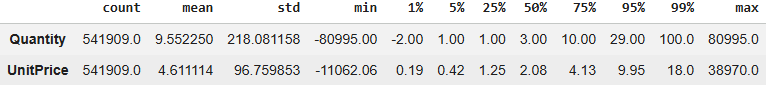
- **Temuan:** Quantity dan UnitPrice sangat tidak seimbang. Quantity median 3 dan persentil ke 99 hanya 100, nilai maksimum 80995 (rata-rata 9,55; std 218,08). Unitprice median 2,08 dan persenti 99 hanya 18 tetapi maksimum 38970 (rata-rata 4,61, std 96,76)
- **Tindakan:** Analisis konteks; bandingkan dengan kuantil dan grafik
- **Apakah dipertahankan, ditransformasi, atau dikelaurkan?** pada tahap ini akan dipertahankan lalu ditransformasi dengan log1p pada frequency dan monetry di tahap data preperation. Nilai ekstrem hanya dikeluarkan jika terbukti sebagai kesalahan data, karena bisa jadi merupakan pembelian grosir yang valid

## Tugas

Buat laporan kualitas data yang berisis minilam lima temuan, bukti berupa angka atau visualisasi, keputusan yang diusulkan, seerta risiko jika keputusan tersebut salah

## Laporan Kualitas Data

1. CustomerID kosong
Bukti: 135.080 baris kosong (24,93%) pada tabel missing values.
- Keputusan yang diusulkan: Dikeluarkan dari analisis pelanggan (RFM), tetapi dipertahankan untuk EDA penjualan.
- Risiko jika salah: Segmentasi hanya mewakili pelanggan yang teridentifikasi dan bisa bias jika pelanggan tanpa ID berperilaku berbeda. Jika dibuang dari seluruh EDA, tren penjualan menjadi tidak lengkap.

2. Invoice pembatalan dan Quantity tidak positif
- Bukti: InvoiceNo diawali C sebanyak 9.288 baris (1,71%) dan Quantity <= 0 sebanyak 10.624 baris (1,96%), dengan minimum -80.995. Kedua kategori dapat tumpang tindih.
- Keputusan yang diusulkan: Dikeluarkan dari baseline pembelian positif setelah diperiksa maknanya sebagai retur atau pembatalan.
- Risiko jika salah: Monetary menjadi penjualan kotor sehingga pelanggan yang sering retur tampak lebih bernilai. Jika dipertahankan, Monetary bisa negatif atau menyimpang.

3. UnitPrice nol atau negatif
- Bukti: UnitPrice <= 0 sebanyak 2.517 baris (0,46%), dengan minimum -11.062,06.
- Keputusan yang diusulkan: Dikeluarkan dari baseline pembelian setelah diperiksa kemungkinan pencatatan khusus.
- Risiko jika salah: Jika baris sebenarnya sah (misalnya barang tanpa biaya), aktivitas pelanggan tercatat lebih rendah. Jika dipertahankan, LineValue nol atau negatif merusak Monetary.

4. Baris duplikat identik
- Bukti: 5.268 baris duplikat (0,97%).
- Keputusan yang diusulkan: Dihapus pada baseline cleaning dengan mencatat jumlah baris yang dihapus.
- Risiko jika salah: Jika sebenarnya item yang sah, Quantity dan Monetary pelanggan menjadi terlalu rendah. Jika dipertahankan padahal salah catat, Monetary menjadi terlalu tinggi.

5. Distribusi Quantity dan UnitPrice sangat menceng dengan nilai ekstrem
- Bukti: Statistik kuantil pada Quantity dan UnitPrice (median jauh di bawah rata-rata, persentil ke-99 jauh di bawah maksimum). Pada histogram data mentah, hampir seluruh data menumpuk pada satu blok di sisi kiri.
- Keputusan yang diusulkan: Outlier tidak otomatis dihapus, dan pengaruhnya dikurangi dengan log1p pada Frequency dan Monetary.
- Risiko jika salah: Jika nilai ekstrem valid dibuang, segmen pelanggan bernilai tinggi hilang. Jika dipertahankan tanpa transformasi, pelanggan ekstrem mendominasi jarak sehingga K-Means membentuk cluster yang tidak seimbang.

6. Deskripsi produk kosong
- Bukti: Description kosong sebanyak 1.454 baris (0,27%).
- Keputusan yang diusulkan: Tidak ditangani khusus karena Description bukan fitur RFM. Pada EDA produk, baris kosong dicatat sebagai tidak diketahui.
- Risiko jika salah: Jika baris dibuang, transaksi yang sah ikut hilang dan Monetary pelanggan sedikit lebih kecil. Dampaknya kecil karena hanya 0,27%.

## Praktikum 5 EDA Transaksi dan Pola Bisnis

## Tujuan

- Membuat visualisasi unvariat, bivariat, dan tren waktu.
- Menghasilkan temuan yang mendukung keputusan data preparation.

In [9]:
# Salinan untuk eksplorasi; belum menjadi data final clustering
eda = df.copy()
eda["LineValue"] = eda["Quantity"] * eda["UnitPrice"]
eda["Month"] = eda["InvoiceDate"].dt.to_period("M").astype(str)


## Tugas EDA

### 11. Buat minimal empat grafik berbeda dan beri judul, label sumbu, serta satu paragraf interpretasi per grafik.

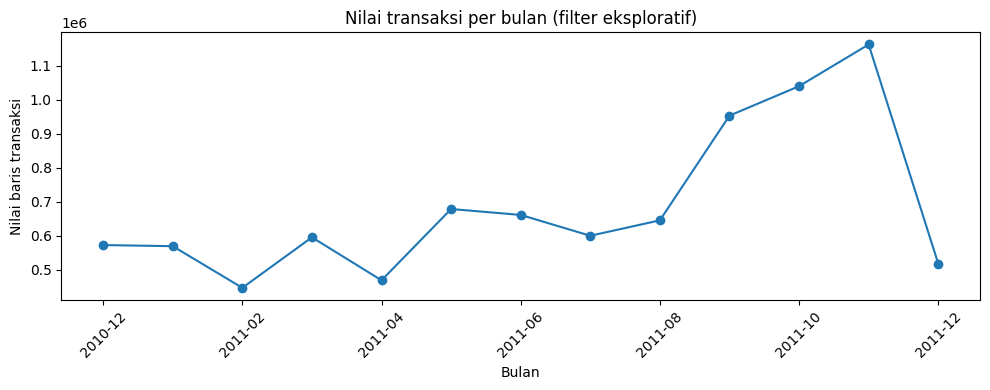

In [10]:
# Tren nilai baris transaksi, gunakan data transaksi yang telah ditandai valid
valid_for_sales = eda[
    eda["CustomerID"].notna() &
    (eda["Quantity"] > 0) &
    (eda["UnitPrice"] > 0) &
    (~eda["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

monthly = valid_for_sales.groupby("Month")["LineValue"].sum()
monthly.plot(kind="line", marker="o", figsize=(10, 4))
plt.title("Nilai transaksi per bulan (filter eksploratif)")
plt.xlabel("Bulan");
plt.ylabel("Nilai baris transaksi")
plt.xticks(rotation=45);
plt.tight_layout();
plt.show()


**Tren Nilai Transaksi Bulanan**

Grafik garis menunjukkan fluktuasi total nilai transaksi per bulan. Nilai transaksi relatif stabil di kisaran 0,45 sampai 0,7 juta pada Desember 2010 sampai Agustus 2011, lalu naik tajam hingga puncak sekitar 1,16 juta pada November 2011 kenaikan ini menunjukkan pola musimam menjelang akhir tahun. Penurunan pada desember 2011 tidak berarti penjualan turun.

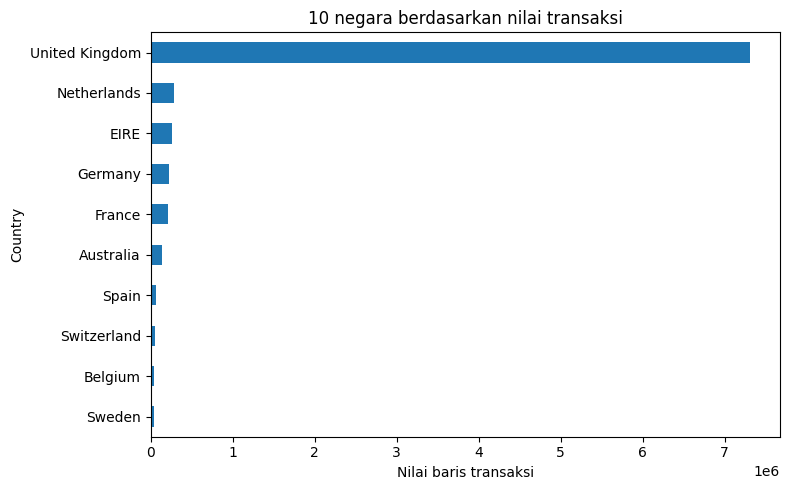

In [11]:
# Negara dengan nilai transaksi tertinggi
country_sales = (
    valid_for_sales.groupby("Country")["LineValue"]
                 .sum().sort_values(ascending=False).head(10))
country_sales.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("10 negara berdasarkan nilai transaksi")
plt.xlabel("Nilai baris transaksi");
plt.tight_layout();
plt.show()


**10 Negara berdasarkan nilai transaksi**

Grafik batang menunjukan United Kingdom mendominasi nilai transaksi dengan sekitar 7,3 juta jauh di atas negara lain seperti Netherlands, EIRE dan Germany yang masing-masing hanya sekitar 0,2 - 0,3 juta, ini menunjukkan pasar toko sangat terkonsentrasi di satu negara sehingg startegi pemasaran utama sebaiknya difokuskan pada pelanggan UK, sedangkan Country kurang berguna sebagai pembeda pelanggan pada clustering.

In [12]:
# Produk dengan kuantitas tertinggi
product_qty = (valid_for_sales.groupby("Description")["Quantity"]
               .sum().sort_values(ascending=False).head(10))
display(product_qty)


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54415
JUMBO BAG RED RETROSPOT,46181
WHITE HANGING HEART T-LIGHT HOLDER,36725
ASSORTED COLOUR BIRD ORNAMENT,35362
PACK OF 72 RETROSPOT CAKE CASES,33693
POPCORN HOLDER,30931
RABBIT NIGHT LIGHT,27202


**Produk dengan kuantitas tertinggi**

Tabel menampilkan daftar produk terlaris berdasarkan total quantity, urutan pertama adalah PAPER RAFT, LITTLE BIRDIE yang tercatat sebanyak 80.995 unit, disusul dibawahnya MEDIUM CERAMIC TOP STORAGE JAR 77.916 unit dan WORD WAR 2 GLIDERS ASSTD DESIGNs 54.415 unit. Dua produk teratas jauh di atas produk lainya yang jumlahnya mencapai puluhan ribu unit kemungkinan berasal dari pembelian grosis dalam jumlah besar. Produk teratas sebagian besar beruoa dekorasi dan hadiah berharga murah, sehingga volume penjualan tinggi tidak selalu berarti nilai transaksinya tinggi.

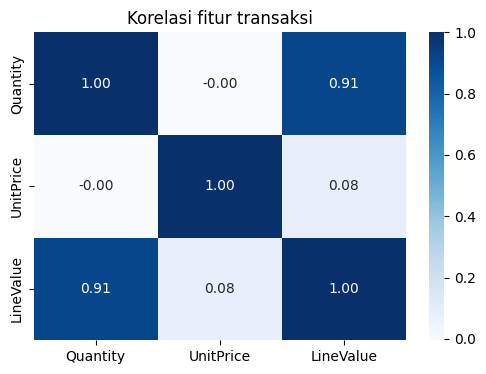

In [13]:
# Korelasi antarfitur numerik pada baris transaksi
corr = valid_for_sales[["Quantity", "UnitPrice", "LineValue"]].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(
    corr, annot=True,
    cmap="Blues",
    fmt=".2f")
plt.title("Korelasi fitur transaksi");
plt.show()


**Korelasi Fitur Transaksi**

Heatmap menunjukan quantity berkolerasi kuat dengan LineValue (0,91), sedangkan UnitPrice hampir tidak berkorelasi dengan quantity (-0,00) dan berkolerasi lemah dengan LineValue 0,08. Artinya nilai transaksi per baris lebih ditentukan olhe jumlah barang yang dibeli daripada harga satuannya. Korelasi tinggi antara Quantity dan LineValue wajar karena LineValue dihitung dari Quantity × UnitPrice, dan korelasi ini tidak membuktikan hubungan sebab-akibat.

### 12. Bandingan distribusi Quantity dan UnitPrice dengan dan tanpa batasan kuantil untuk visualisasi

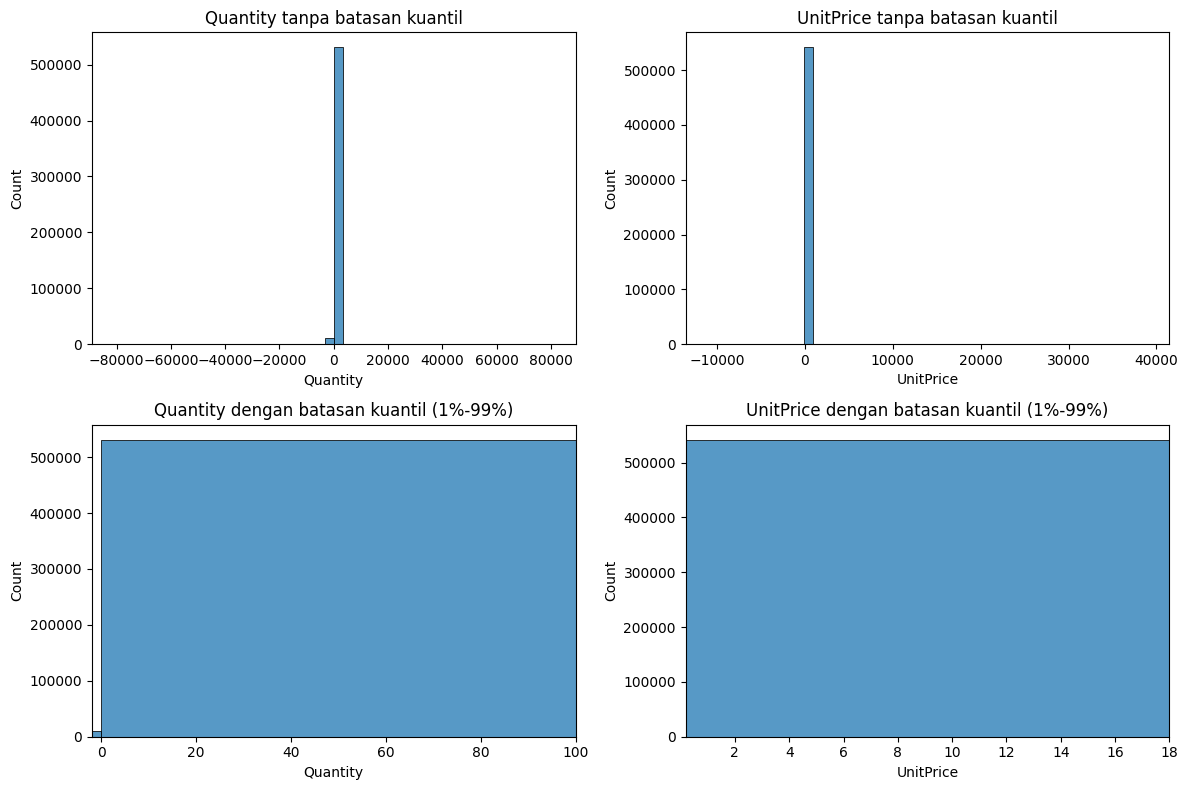

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Tanpa batasan kuantil
sns.histplot(df["Quantity"].dropna(), bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Quantity tanpa batasan kuantil")
sns.histplot(df["UnitPrice"].dropna(), bins=50, ax=axes[0, 1])
axes[0, 1].set_title("UnitPrice tanpa batasan kuantil")

# Dengan batasan kuantil 1% sampai 99%
sns.histplot(df["Quantity"].dropna(), bins=50, ax=axes[1, 0])
axes[1, 0].set_xlim(df["Quantity"].quantile(.01), df["Quantity"].quantile(.99))
axes[1, 0].set_title("Quantity dengan batasan kuantil (1%-99%)")
sns.histplot(df["UnitPrice"].dropna(), bins=50, ax=axes[1, 1])
axes[1, 1].set_xlim(df["UnitPrice"].quantile(.01), df["UnitPrice"].quantile(.99))
axes[1, 1].set_title("UnitPrice dengan batasan kuantil (1%-99%)")

plt.tight_layout()
plt.show()

Tanpa batasan kuantil, sumbu x histogram mengikuti nilai ekstrem (Quantity dari -80.995 sampai 80.995, UnitPrice dari -11.062 sampai 38.970), sehingga hampir seluruh data menumpuk pada satu batang sempit dan bentuk distribusinya tidak terbaca. Dengan batasan kuantil 1% sampai 99% (Quantity sekitar -2 sampai 100, UnitPrice sekitar 0,19 sampai 18), sumbu x berfokus pada rentang yang mewakili mayoritas data, sehingga konsentrasi data pada nilai kecil lebih mudah dilihat. Batasan ini hanya untuk visualisasi dan tidak menghapus data, sehingga nilai ekstrem tetap ada dan ditangani pada tahap Data Preparation.

### 13. Temukan dua pola yang mungkin penting bagi pengelola toko.


**Pola 1**
Penjualan bersifat musiman dan memuncak mejelang akhir tahun, dengan titik puncak sekitar 1,16 juta pada november 2011. Pengelola toko perlu menyiapkan stok, promosi dan program loyalitas sebelum priode tersebut.

**Pola 2**
Pasar menjadi terkonsentrasi di Unite Kingdom sekitar 7,3 juta, sedangkan negara lain hanya sekitar 0,2 sampai 0,3 juta. Strategi utama pemasaran baiknya difokuskan pada UK, sementara pasar luar negeri dikembangkan secara terpisah.

### 14. Nyatakan apakah hasil EDA mengubah rencana awal fitur atau pembersihan data.

Hasil EDA tidak mengubah rencana fitur (tetap Recency, Frequency, dan Monetary), tetapi memperkuat beberapa keputusan. Pertama, distribusi yang sangat menceng mendukung transformasi log1p pada Frequency dan Monetary. Kedua, aturan pembersihan baseline (menghapus duplikat, CustomerID kosong, invoice pembatalan, serta Quantity dan UnitPrice yang tidak positif) tetap dipertahankan, dan outlier tidak dihapus otomatis. Ketiga, Country tidak dijadikan fitur karena didominasi satu negara. Keempat, data yang berakhir pada 9 Desember 2011 mengonfirmasi tanggal acuan Recency 10 Desember 2011.

## Praktikum 6 Data Preparation: Pembersihan dan Nilai Transaksi


## Tujuan

- Membuat aturan pembersihan yang transparan dan dapat diulang.
- Menghasilkan dataset transaksi yang siap diagregasi menjadi fitur pelanggan.


## Aturan awal yang digunakan

Aturan berikut merupakan baseline pembelajaran, bukan satu-satunya aturan yang benar. Mahasiswa harus menyebutkan konsekuensinya dan dapat mengusulkan alternatif.
- CustomerID kosong tidak dapat digunakan untuk profil per pelanggan, sehingga dikeluarkan dari tabel analisis pelanggan.
- InvoiceNo yang diawali C diperlakukan sebagai indikasi pembatalan dan dikeluarkan dari baseline penjualan positif.
- Quantity harus lebih dari nol dan UnitPrice harus lebih dari nol untuk baseline transaksi pembelian.
- Baris duplikat identik diperiksa dan dihapus jika dinilai merupakan duplikasi pencatatan.
- Outlier tidak otomatis dihapus; penanganannya diputuskan setelah melihat distribusi dan tujuan analisis.


## Kode praktik

In [15]:
# Salin data; pastikan tanggal sudah datetime
clean = df.copy()
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")
clean["CustomerID"] = clean["CustomerID"].astype("string").str.strip()

rows_before = len(clean)
duplicate_count = clean.duplicated().sum()
clean = clean.drop_duplicates()

# Baris yang dapat dipakai untuk profil pelanggan
clean = clean[clean["CustomerID"].notna()].copy()
clean = clean[clean["InvoiceDate"].notna()].copy()

# Baseline: transaksi pembelian positif, bukan invoice pembatalan
is_cancellation = clean["InvoiceNo"].astype(str).str.startswith("C")
clean = clean[~is_cancellation]
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]

clean["LineValue"] = clean["Quantity"] * clean["UnitPrice"]

print("Baris awal:", rows_before)
print("Duplikat identik terdeteksi:", duplicate_count)
print("Baris setelah baseline cleaning:", len(clean))
print("Pelanggan tersedia:", clean["CustomerID"].nunique())
display(clean.head())


Baris awal: 541909
Duplikat identik terdeteksi: 5268
Baris setelah baseline cleaning: 392692
Pelanggan tersedia: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## Pemeriksaan Setelah Cleaning

In [16]:
assert clean["CustomerID"].notna().all()
assert clean["InvoiceDate"].notna().all()
assert (clean["Quantity"] > 0).all()
assert (clean["UnitPrice"] > 0).all()
assert (clean["LineValue"] > 0).all()

print(clean[["Quantity", "UnitPrice", "LineValue"]].describe())


            Quantity      UnitPrice      LineValue
count  392692.000000  392692.000000  392692.000000
mean       13.119702       3.125914      22.631500
std       180.492832      22.241836     311.099224
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.950000
50%         6.000000       1.950000      12.450000
75%        12.000000       3.750000      19.800000
max     80995.000000    8142.750000  168469.600000


## Tugas

### Bandingkan jumlah baris dan jumlah pelanggan sebelum serta sesudah cleaning.

- 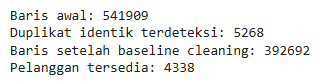
- Sebelum cleaning 541.909 baris.
- Setelah cleaning tersisa 392.692 baris.
- Dikeluarkan total 149.217 baris (27,54%).
- Jumlah pelanggan unik turun dari 4.372 menjadi 4.338.  - Sebanyak 34 pelanggan (0,78% hilang) karena seluruh aris transaksi berupa pembatalan atau harga tidak valid, sehingga tidak menyisakan pembelian positif.
- **Analisis Penururnan**Penurunan baris jauh lebih besar daripada penurunan pelanggan, karena sebagian besar baris yang dibuang (terutama CustomerID kosong dan duplikat) tidak mengurangi jumlah pelanggan teridentifikasi secara signifikan. Setiap pelanggan yang tersisa kini memiliki seluruh baris berupa pembelian positif dengan harga valid.

### Buat tabel log pembersihan: aturan, jumlah baris terdampak, alasan, risiko.

In [17]:
tmp = df.copy()
tmp["InvoiceDate"] = pd.to_datetime(tmp["InvoiceDate"], errors="coerce")

aturan_cleaning = [
    ("Hapus duplikat identik",
     lambda d: ~d.duplicated(),
     "Baris identik pada semua kolom kemungkinan duplikasi pencatatan",
     "Jika sebenarnya item sah, Quantity dan Monetary pelanggan menjadi terlalu rendah"),
    ("Keluarkan CustomerID kosong",
     lambda d: d["CustomerID"].notna(),
     "Tanpa identitas, transaksi tidak dapat diagregasi per pelanggan",
     "Segmentasi tidak mewakili pembeli tanpa ID dan bisa bias"),
    ("Keluarkan InvoiceDate kosong",
     lambda d: d["InvoiceDate"].notna(),
     "Tanggal diperlukan untuk menghitung Recency",
     "Tidak ada dampak jika tidak ada baris yang terkena"),
    ("Keluarkan invoice pembatalan (awalan C)",
     lambda d: ~d["InvoiceNo"].astype(str).str.startswith("C"),
     "Pembatalan bukan transaksi pembelian",
     "Monetary menjadi penjualan kotor dan pelanggan sering membatalkan tampak lebih bernilai"),
    ("Keluarkan Quantity <= 0",
     lambda d: d["Quantity"] > 0,
     "Retur atau koreksi stok, bukan pembelian",
     "Retur tidak dikurangkan dari belanja pelanggan"),
    ("Keluarkan UnitPrice <= 0",
     lambda d: d["UnitPrice"] > 0,
     "LineValue nol atau negatif tidak mencerminkan nilai belanja",
     "Jika barang tanpa biaya yang sah, aktivitas pelanggan terhitung lebih rendah"),
]

log_rows = []
for aturan, keep, alasan, risiko in aturan_cleaning:
    sebelum = len(tmp)
    tmp = tmp[keep(tmp)]
    log_rows.append({
        "Aturan": aturan,
        "Baris terdampak": sebelum - len(tmp),
        "Persen dari data awal (%)": round((sebelum - len(tmp)) / len(df) * 100, 2),
        "Baris tersisa": len(tmp),
        "Alasan": alasan,
        "Risiko": risiko,
    })

log_cleaning = pd.DataFrame(log_rows)
display(log_cleaning)

print("Total baris dikeluarkan:", log_cleaning["Baris terdampak"].sum())
print("Cocok dengan clean:", len(tmp) == len(clean))

,Aturan,Baris terdampak,Persen dari data awal (%),Baris tersisa,Alasan,Risiko
0,Hapus duplikat identik,5268,0.97,536641,Baris identik pada semua kolom kemungkinan dup...,"Jika sebenarnya item sah, Quantity dan Monetar..."
1,Keluarkan CustomerID kosong,135037,24.92,401604,"Tanpa identitas, transaksi tidak dapat diagreg...",Segmentasi tidak mewakili pembeli tanpa ID dan...
2,Keluarkan InvoiceDate kosong,0,0.00,401604,Tanggal diperlukan untuk menghitung Recency,Tidak ada dampak jika tidak ada baris yang ter...
3,Keluarkan invoice pembatalan (awalan C),8872,1.64,392732,Pembatalan bukan transaksi pembelian,Monetary menjadi penjualan kotor dan pelanggan...
4,Keluarkan Quantity <= 0,0,0.00,392732,"Retur atau koreksi stok, bukan pembelian",Retur tidak dikurangkan dari belanja pelanggan
5,Keluarkan UnitPrice <= 0,40,0.01,392692,LineValue nol atau negatif tidak mencerminkan ...,"Jika barang tanpa biaya yang sah, aktivitas pe..."


Total baris dikeluarkan: 149217
Cocok dengan clean: True


### Jelaskan mengapa data bersih harus tetap disimpan terpisah dari data mentah.


Data mentah harus tetap disimpan terpisah dari data bersih karena berfungsi menjadi sumber kebenaran. Dengan memisahkannya, setiap keputusan cleaning dapat ditelusuri dan diaudit, misalnya 149.217 baris yang dikeluarkan masih bisa diperiksa kembali. Jika aturan cleaning ternyata kurang tepat, proses dapat diulang dari data mentah tanpa mengunduh ulang. Selain itu, baris yang dibuang untuk RFM, seperti baris tanpa CustomerID atau invoice pembatalan, tetap berguna untuk analisis lain. Jika data mentah ditimpa, informasi yang hilang tidak dapat dipulihkan.

## Praktikum 7 Membentuk Fitur Pelanggan RFM

## Tujuan

- Mengubah data transaksi menjadi satu baris per pelanggan.
- Menghitung Recency, Frequency, dan Monetary.


## Konsep RFM

- **Recency:** Jumlah hari antara tanggal acuan dan tanggal terakhir pelanggan (catatan: Nilai kecil berarti transaksi lebih baru).
- **Frequency**: Jumlah InvoiceNo unik per pelanggan (catatan: Dapat menggunakan jumlah invoice unik sebagai proksi frekuensi).
- **Monetary:** Jumlah LineValue per pelanggan pada data transaksi yang dipilih (catatan: interpretasi bergantung pada aturan pembatalan/retur).

## Kode Praktik

In [18]:
# Tanggal acuan dibuat satu hari setelah tanggal transaksi terakhir
reference_date = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineValue", "sum")
)
rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()

print("Ukuran tabel RFM:", rfm.shape)
display(rfm.head())
display(rfm.describe().T)
print("CustomerID unik:", rfm.index.nunique())


Ukuran tabel RFM: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,3,7,4310.00
12348.0,76,4,1797.24
12349.0,19,1,1757.55
12350.0,311,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.00,18.0000,51.00,142.7500,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


CustomerID unik: 4338


## EDA khusus RFM

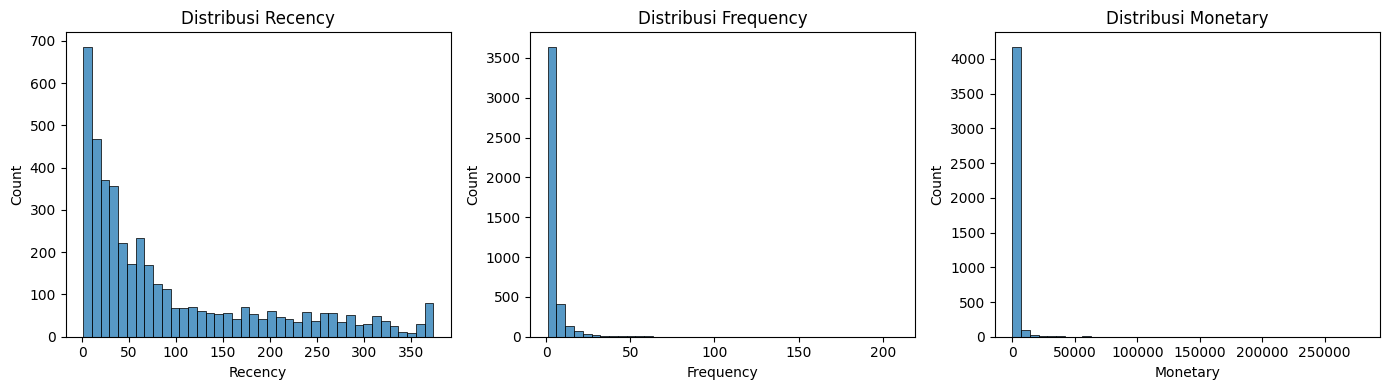

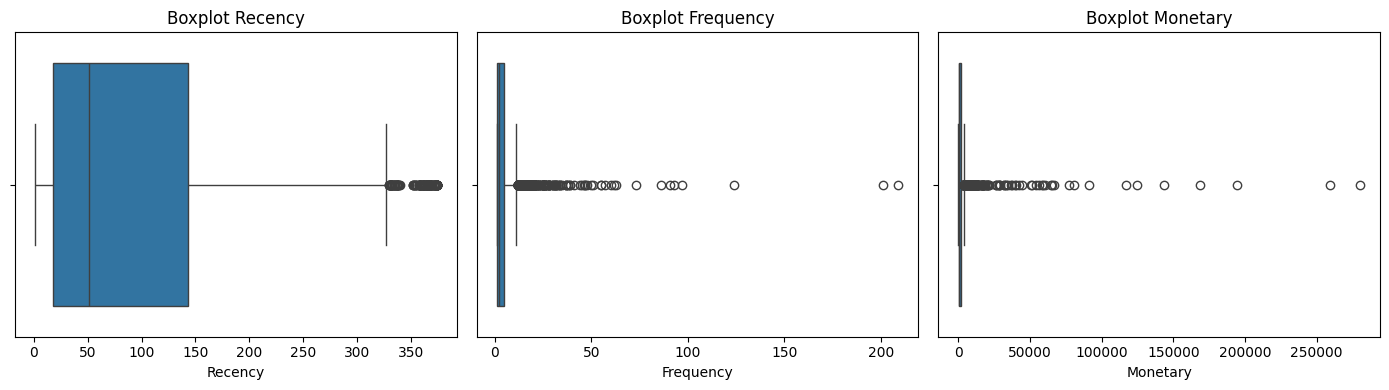

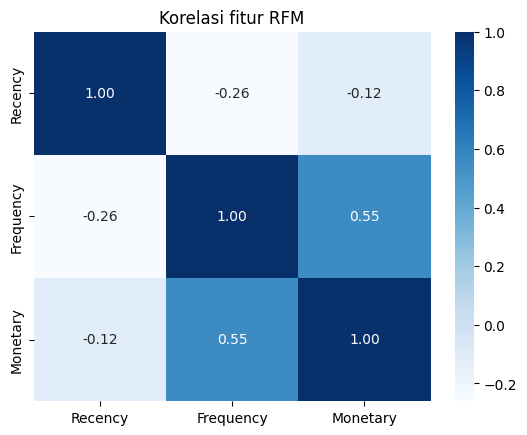

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout();
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"Boxplot {col}")
plt.tight_layout();
plt.show()

sns.heatmap(rfm.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur RFM");
plt.show()


## Menangani Skewness

Frequency dan Monetary biasanya memiliki distribusi menceng ke kanan. Transformasi log1p dapat mengurangi dominasi pelanggan bernilai sangat tinggi. Recency umumnya dipertahankan pada skala asli sebelum scaling. Bandingkan distribusi sebelum dan sesudah transformasi.

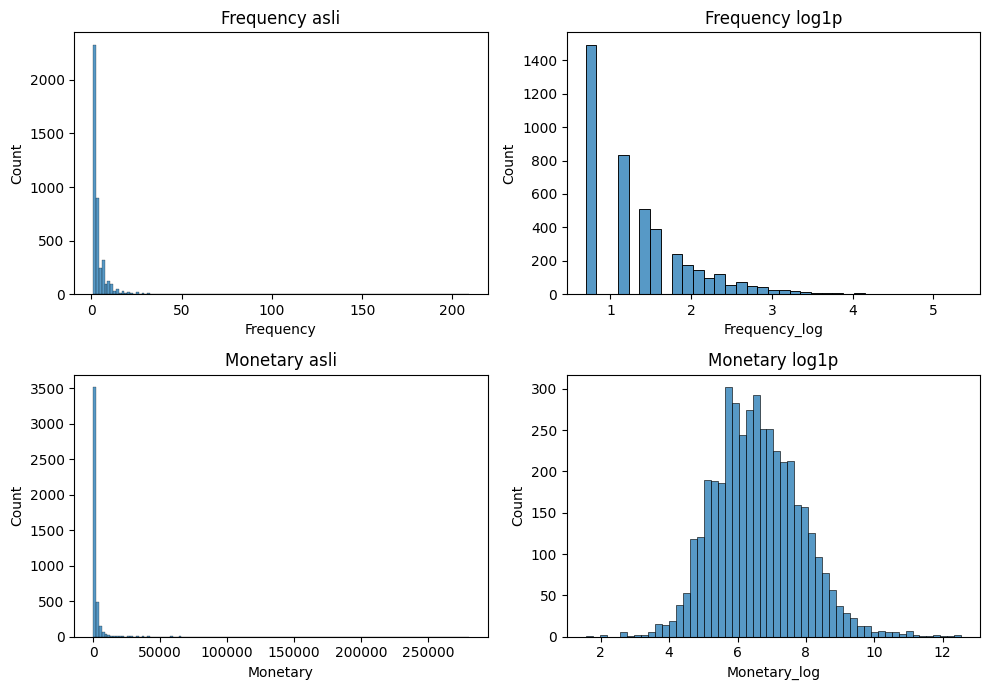

In [20]:
rfm_model = rfm.copy()
rfm_model["Frequency_log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_log"] = np.log1p(rfm_model["Monetary"])

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(rfm_model["Frequency"], ax=axes[0,0])
axes[0,0].set_title("Frequency asli")
sns.histplot(rfm_model["Frequency_log"], ax=axes[0,1])
axes[0,1].set_title("Frequency log1p")

sns.histplot(rfm_model["Monetary"], ax=axes[1,0])
axes[1,0].set_title("Monetary asli")
sns.histplot(rfm_model["Monetary_log"], ax=axes[1,1])
axes[1,1].set_title("Monetary log1p")
plt.tight_layout();
plt.show()



## Menentukan Fitur Final

Untuk perbandingan algoritma, gunakan Recency, Frequency_log, dan Monetary_log. Simpan tabel RFM asli agar interpretasi cluster tetap menggunakan satuan yang mudah dipahami.

In [21]:
features = rfm_model[["Recency", "Frequency_log", "Monetary_log"]].copy()
print(features.isna().sum())
display(features.head())


Recency          0
Frequency_log    0
Monetary_log     0
dtype: int64


,Recency,Frequency_log,Monetary_log
CustomerID,,,
12346.0,326,0.693147,11.253955
12347.0,3,2.079442,8.368925
12348.0,76,1.609438,7.494564
12349.0,19,0.693147,7.472245
12350.0,311,0.693147,5.815324


## Tugas

- Jelaskan perbedaan unit analisis pada dataset transaksi dan tabel RFM.
- Interpretasikan pelanggan dengan Recency kecil tetapi Frequency dan Monetary rendah.
- Bandingkan histogram Frequency dan Monetary sebelum dan sesudah log1p.
- Jelaskan mengapa CustomerID tidak dimasukkan ke features.


- Pada dataset transaksi, satu baris mewakili satu item produk dalam satu invoice, sehingga satu pelanggan bisa muncul pada banyak baris (392.692 baris setelah cleaning). Pada tabel RFM, satu baris mewakili satu pelanggan (satu CustomerID) dengan tiga ringkasan perilaku, yaitu Recency, Frequency, dan Monetary, sehingga ukurannya menjadi 4.338 baris x 3 kolom. Karena tujuan analisis adalah mengelompokkan pelanggan, bukan transaksi, data harus diagregasi dulu ke tingkat pelanggan.

- Pelanggan ini baru berbelanja belum lama ini, tetapi jarang membeli dan nilainya kecil, kemungkinan pelanggan baru atau pembeli sesekali. Mereka berpotensi dikembangkan lewat onboarding dan rekomendasi produk, dengan validasi pada periode data yang lebih panjang.

- Frequency asli sangat menumpuk pada nilai kecil (sekitar 1.500 pelanggan hanya bertransaksi satu kali) dengan ekor panjang sampai 209, sehingga bentuknya hampir tidak terbaca. Setelah log1p, rentangnya menyempit menjadi sekitar 0,69 sampai 5,3 dan sebarannya lebih terbaca, walaupun masih menceng ke kanan dan berbentuk batang-batang terpisah karena Frequency berupa bilangan bulat. Monetary asli juga menumpuk dekat nol dengan ekor sampai sekitar 280.000. Setelah log1p, distribusinya mendekati bentuk lonceng yang cukup simetris dengan pusat sekitar 6 sampai 7. Dengan demikian, log1p mengurangi dominasi pelanggan bernilai sangat tinggi, dan efeknya lebih kuat pada Monetary daripada Frequency.

- CustomerID hanyalah pengenal, bukan ukuran perilaku. Angkanya tidak memiliki makna jarak atau besaran, sehingga ID 12346 dan 12347 yang berdekatan tidak berarti pelanggannya mirip. Jika dimasukkan, algoritma berbasis jarak akan membentuk cluster berdasarkan nomor ID, bukan perilaku belanja, sehingga hasilnya menyesatkan. CustomerID cukup dipakai sebagai indeks untuk memetakan label cluster kembali ke tabel RFM.

## Praktikum 8 Modeling K-Means


## Tujuan

- Memahami clustering berbasis centroid.
- Menerapkan scaling dan membandingkan beberapa nilai k.


## Kode praktik

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

results_kmeans = []
models_kmeans = {}
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)
    results_kmeans.append({
        "k": k, "inertia": model.inertia_,
        "silhouette": sil, "davies_bouldin": dbi
    })
    models_kmeans[k] = model

metrics_kmeans = pd.DataFrame(results_kmeans)
display(metrics_kmeans)


,k,inertia,silhouette,davies_bouldin
0,2,6874.047281,0.406287,0.915325
1,3,4299.200976,0.415654,0.824915
2,4,3242.934841,0.379421,0.859949
3,5,2760.683135,0.343462,0.940980
4,6,2396.802728,0.331644,0.969220
5,7,2167.087137,0.300838,1.018503


## Elbow dan Silhouette

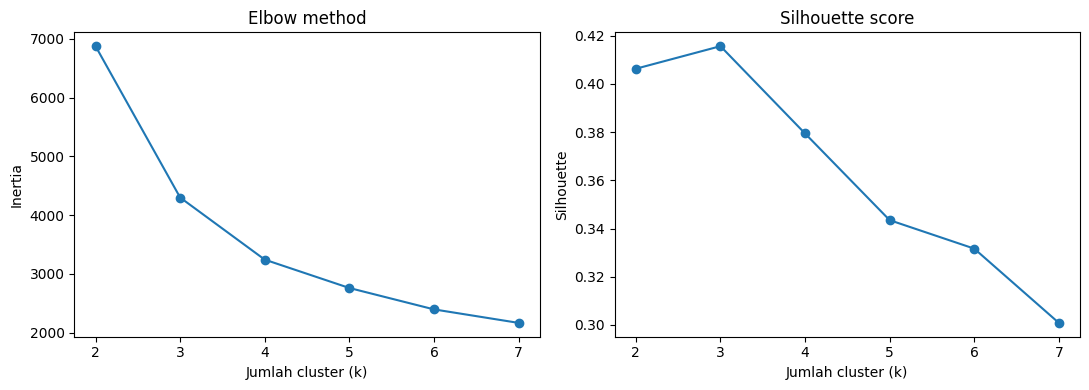

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(metrics_kmeans["k"], metrics_kmeans["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(metrics_kmeans["k"], metrics_kmeans["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()


## Memilih Model Sementara

In [24]:
# Pilih k berdasarkan kombinasi metrik dan interpretasi.
# Contoh otomatis di bawah memilih silhouette tertinggi; keputusan final tetap harus ditinjau.
best_k = int(metrics_kmeans.loc[metrics_kmeans["silhouette"].idxmax(), "k"])
kmeans_model = models_kmeans[best_k]
rfm["KMeans_Cluster"] = kmeans_model.labels_
print("k terpilih sementara:", best_k)
display(rfm.groupby("KMeans_Cluster")[["Recency","Frequency","Monetary"]]
        .median().round(2))


k terpilih sementara: 3


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,46.0,2.0,508.80
1,253.0,1.0,290.46
2,18.0,7.0,2570.50


## Visualisasi dua fitur

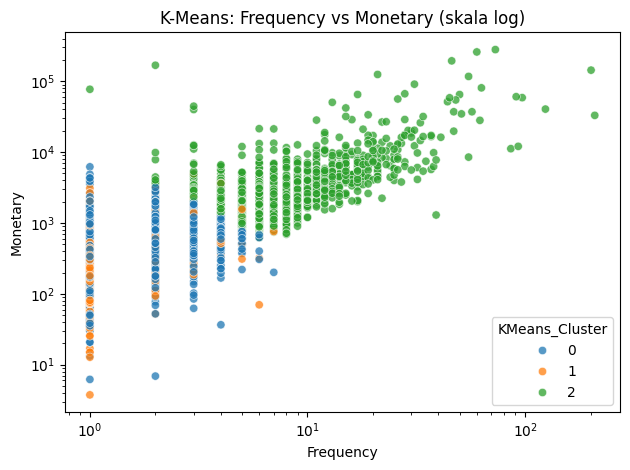

In [25]:
sns.scatterplot(
    data=rfm, x="Frequency", y="Monetary",
    hue="KMeans_Cluster", palette="tab10", alpha=.75
)
plt.xscale("log")
plt.yscale("log")
plt.title("K-Means: Frequency vs Monetary (skala log)")
plt.tight_layout(); plt.show()


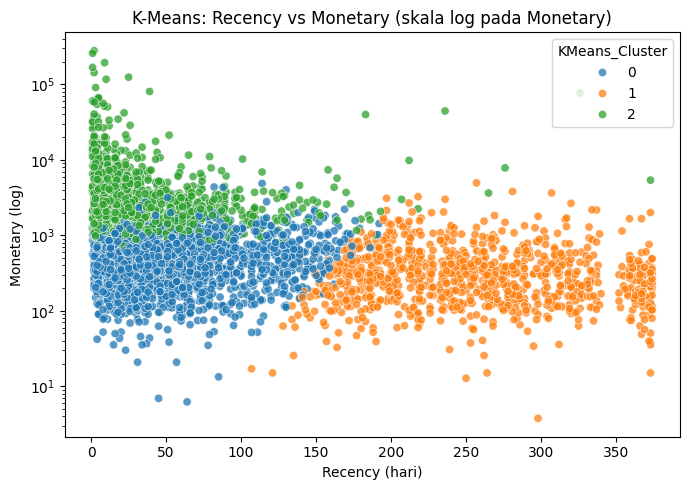

In [26]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary",
                hue="KMeans_Cluster", palette="tab10", alpha=.75)
plt.yscale("log")
plt.title("K-Means: Recency vs Monetary (skala log pada Monetary)")
plt.xlabel("Recency (hari)"); plt.ylabel("Monetary (log)")
plt.tight_layout(); plt.show()

## Pertanyaan

1. Apa makna inertia dan mengapa nilainya cenderung turun saat k bertambah?
- **Makna:** intertia (Within-Cluster Sum of Squares)mengukur total jarak kuadrat antara setiap titik data dengan pusat cluster (centroid)nya. Makin kecil nilainya makin rapat data di dalam cluster.
- karena ketika jumlah k bertambah, jarak rata-rata ke centroid terdekat akan mengecil karena area cluster dipecah menjadi lebih banyak bagian. Jikan k = N (jumlah data) intertia menjadi nol.

2. Apa kelebihan dan keterbatasan Elbow method?
- **Kelebihan** sangat intuitif, cepat dan mudah dipahami secara visual untuk melihat titik dimnishing returns (penurunan intertia yang mulai melambat).
- **Keterbatasana** bersifat subjektif karena siku pada grafik tidak selalu terlihat jelas atau tajam, sehingga sulit menentukan k optimal jika grafiknya melengkung secara landai.

3. Mengapa hasil cluster perlu ditafsirkan menggunakan RFM asli?
Fitur yang digunakan saat pemodelan telah melalui transformasi (log1p) dan pemrosesan skala (StandardScaler) sehingga angkanya kehilangan satuan bisnis nyata, oleh karena itu hasil pengelompokan perlu ditafsirkan kembali menggunakan nilai RFM asli (seperti Recency dalam satuan hari atau Monetary dalam skala mata uang) guna memudahkan tim bisnis dan pemasaran dalam memahami profil aktual serta merancang strategi untuk tiap segmen pelanggan.

4. Apakah k dengan Silhouette tertinggi otomatis menjadi pilihan terbaik? Jelaskan.
Tidak, metrik silhouette hanya menilai kerapatan dan pemisahan secara matematis. Pilihan terbaik mempertimbangkan relevansi bisnis, apakah kelompok yang terbentuk dapat diberi nama, mudah dibedakkan profilnya, dan dapat ditindaklanjuti dengan startegi pemasaran nyata.

## Praktikum 9 Modeling K-Medoids

## Konsep

K-Medoids memilih anggota data aktual sebagai pusat cluster (medoid). Berbeda dari K-Means yang menggunakan rata-rata centroid, K-Medoids dapat lebih tahan terhadap outlier dalam sejumlah kondisi, tetapi implementasinya bisa lebih mahal secara komputasi.

## Pilihan Implementasi

In [27]:
# Pilihan A — coba instalasi paket
%pip -q install scikit-learn-extra

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Jalankan jika paket berhasil diinstal
kmedoids_results = []
kmedoids_models = {}
for k in range(2, 8):
    model = KMedoids(n_clusters=k, random_state=42,
                     metric="euclidean", method="alternate",
                     init="k-medoids++")
    labels = model.fit_predict(X_scaled)
    kmedoids_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    kmedoids_models[k] = model

metrics_kmedoids = pd.DataFrame(kmedoids_results)
display(metrics_kmedoids)


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


,k,silhouette,davies_bouldin
0,2,0.395125,0.915266
1,3,0.413914,0.825647
2,4,0.372484,0.868534
3,5,0.354828,0.964474
4,6,0.291199,1.109641
5,7,0.319186,1.014629


## Jika paket tidak kompatibel

Untuk latihan konsep, gunakan sampel acak terbatas, misalnya 300–500 pelanggan, lalu implementasikan PAM (Partitioning Around Medoids) sederhana atau gunakan lingkungan Python yang kompatibel. Hindari menjalankan perhitungan jarak kuadrat penuh pada seluruh pelanggan tanpa mempertimbangkan memori dan waktu

In [28]:
# Sampel untuk eksperimen K-Medoids agar komputasi lebih ringan
sample_idx = features.sample(n=min(400, len(features)), random_state=42).index
X_sample = features.loc[sample_idx]
X_sample_scaled = StandardScaler().fit_transform(X_sample)
print("Ukuran sampel:", X_sample_scaled.shape)


Ukuran sampel: (400, 3)


## Tugas

1. Bandingkan prinsip centroid K-Means dengan medoid K-Medoids.
- **K-Means** pusat cluster berupa nilai rata-rata (mean) imaginer dari seluruh data di cluster tersebut. Titik pusat ini biasanya tidak mewakili data nyata mana pun dalam dataset dan sangat sensitif terhadap nilai ekstrem (outlier).
- **K-Medoids** Pusat cluster (medoid) merupakan data aktual yang ada dalam dataset, yaitu objek yang paling terpusat dalam cluster. Pendekatan ini lebih tahan (robust) terhadap nilai ekstrem.
2. Gunakan jumlah cluster yang sama untuk perbandingan awal.
Perbandingan Metrik Evaluasi (k = 3)
- **K-Medoids** Seluruh data sihloutte score 0.4139, Davies-Bouldin Index 0.8256.
- **k-Means** Silhouette score 0.4156, Davies Boulding index 0.8249.
3. Catat waktu komputasi, Silhouette Score, Davies–Bouldin Index, dan interpretasi cluster.
- K-Means memproses jauh lebih cepat. K-Medoids membutuhkan waktu dan memori yang lebih besar karena harus menghitung matriks jarak antar-objek. Namun, kedua algoritma menghasilkan kualitas pemisahan cluster yang sangat mirip.
4. Jelaskan mengapa perbandingan pada sampel harus disebutkan sebagai keterbatasan.
- Sampel acak (misal 400 data) belum tentu sepenuhnya mewakili sebaran, variabilitas, dan outlier dari keseluruhan 4.338 pelanggan.
Evaluasi metrik dan profil cluster pada sampel dapat bergeser (bias) jika dibandingkan langsung dengan algoritma yang dilatih menggunakan seluruh dataset.


## Praktikum 10 Modeling Hierarchical Clustering

## Konsep

Agglomerative Hierarchical Clustering memulai dari setiap observasi sebagai cluster kecil, kemudian menggabungkan cluster secara bertahap berdasarkan aturan linkage. Dendrogram membantu memvisualisasikan penggabungan, tetapi dendrogram penuh dapat berat untuk dataset besar.


## Kode Praktik

## Linkage ward

In [29]:
from sklearn.cluster import AgglomerativeClustering

hier_results = []
hier_models = {}
for k in range(2, 8):
    model = AgglomerativeClustering(
        n_clusters=k, linkage="ward"
    )
    labels = model.fit_predict(X_scaled)
    hier_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    hier_models[k] = model

metrics_hier = pd.DataFrame(hier_results)
display(metrics_hier)


,k,silhouette,davies_bouldin
0,2,0.382603,0.956354
1,3,0.364925,0.855645
2,4,0.336078,0.921027
3,5,0.290059,1.022131
4,6,0.275625,0.998258
5,7,0.223598,1.084314


## Visualisasi

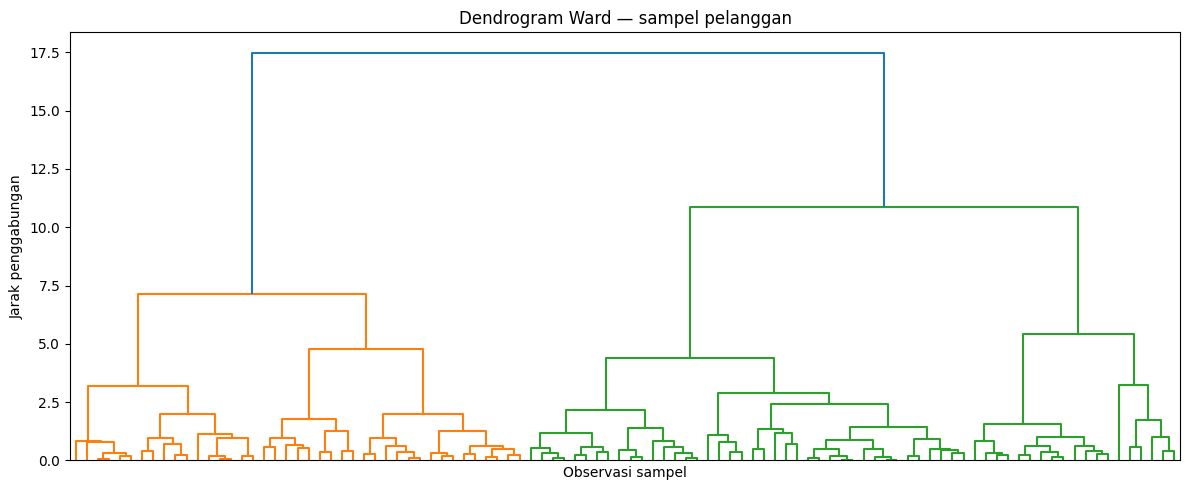

In [30]:
# Visualisasi pada sampel kecil agar tidak terlalu padat
from scipy.cluster.hierarchy import linkage, dendrogram

n_sample = min(100, len(X_scaled))
rng = np.random.default_rng(42)
sample_positions = rng.choice(len(X_scaled), size=n_sample, replace=False)
Z = linkage(X_scaled[sample_positions], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram Ward — sampel pelanggan")
plt.xlabel("Observasi sampel"); plt.ylabel("Jarak penggabungan")
plt.tight_layout();
plt.show()


## Linkage Complete

In [31]:
from sklearn.cluster import AgglomerativeClustering
hier_results_complete = []
hier_models_complete = {}

for k in range(2, 8):
    model = AgglomerativeClustering(
         n_clusters=k, linkage="complete"
    )
    labels = model.fit_predict(X_scaled)
    hier_results_complete.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    hier_models_complete[k] = model

# Simpan ke DataFrame khusus Complete Linkage
metrics_hier_complete = pd.DataFrame(hier_results_complete)
display(metrics_hier_complete)

,k,silhouette,davies_bouldin
0,2,0.403027,0.686962
1,3,0.255381,1.124201
2,4,0.255530,1.027891
3,5,0.240476,0.931933
4,6,0.229361,0.820910
5,7,0.261720,0.885540


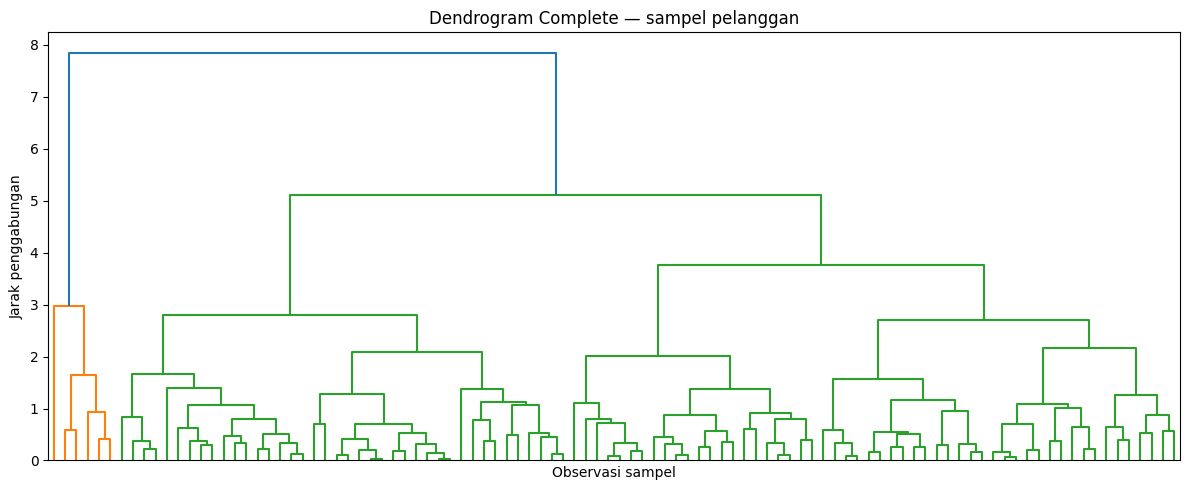

In [32]:
from scipy.cluster.hierarchy import linkage, dendrogram

n_sample = min(100, len(X_scaled))
rng = np.random.default_rng(42)
sample_positions = rng.choice(len(X_scaled), size=n_sample, replace=False)
Z = linkage(X_scaled[sample_positions], method="complete")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram Complete — sampel pelanggan")
plt.xlabel("Observasi sampel"); plt.ylabel("Jarak penggabungan")
plt.tight_layout();
plt.show()

## Tugas

1. Bandingkan linkage Ward dengan satu linkage lain, misalnya average, pada sampel yang sama.
- **Linkage ward** meminimalkan total varians di dalam cluster yang digabungkan, sehingga cenderung membentuk kelompok yang seimbang dan berbentuk bola (spherical). Metode ini sangat stabil untuk memisahkan segmen pelanggan berdasarkan jarak numerik.
- **Linkage Complete** Mengukur jarak maksimum antar-pasangan observasi dari dua cluster berbeda. Metode ini sangat sensitif terhadap nilai ekstrem (outlier) dan cenderung membentuk cluster yang tidak seimbang ukurannya.

2. Jelaskan apa yang ditampilkan oleh dendrogram dan mengapa tinggi penggabungan penting.
- Dendrogram menampilkan pohon hierarki (tree diagram) yang menggambarkan tahapan penggabungan data dari titik individual hingga menjadi satu cluster besar, di mana tinggi penggabungan (sumbu y) sangat penting karena menunjukkan tingkat ketidakmiripan; semakin tinggi garis vertikal saat dua cluster bergabung, semakin jauh perbedaan karakteristik di antara keduanya, sehingga titik potong pada garis vertikal yang panjang dapat membantu menentukan jumlah cluster yang optimal.

3. Bandingkan metrik Hierarchical Clustering dengan K-Means pada jumlah cluster yang sama.
- **Hierarchical clustering** (ward k = 3) silhouette score 0.3649, davies voulding index 0.8556.
- **K-Means (k=3)** Silhouette Score 0.4156, Davies–Bouldin Index 0.8249

pada julah cluster yang sama  (k=3) k-means memberikan hasil pemisahan cluster yang sedikit lebih optimal secara sistematis (silhouette lebih tinggi dan davies bouldin lebih rendah) dibandingkan hierarchical clustering.

## Praktikum 11 Modeling DBSCAN

## Konsep

DBSCAN mengelompokkan titik berdasarkan kepadatan. Parameter eps menentukan radius lingkungan dan min_samples menentukan jumlah minimum titik untuk membentuk wilayah padat. Algoritma dapat menandai observasi sebagai noise (-1), dan tidak perlu menetapkan jumlah cluster di awal.

## Kode Praktik

In [33]:
from sklearn.cluster import DBSCAN

dbscan_results = []
dbscan_models = {}
for eps in [0.3, 0.5, 0.7, 1.0, 1.3]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    # Silhouette dihitung hanya bila terdapat >=2 cluster non-noise
    non_noise = labels != -1
    sil = np.nan
    dbi = np.nan
    if len(set(labels[non_noise])) >= 2 and non_noise.sum() > 2:
        sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
        dbi = davies_bouldin_score(X_scaled[non_noise], labels[non_noise])
    dbscan_results.append({
        "eps": eps, "min_samples": 10, "n_clusters": n_clusters,
        "noise_pct": noise_pct, "silhouette_non_noise": sil,
        "davies_bouldin_non_noise": dbi
    })
    dbscan_models[eps] = model

metrics_dbscan = pd.DataFrame(dbscan_results)
display(metrics_dbscan)


,eps,min_samples,n_clusters,noise_pct,silhouette_non_noise,davies_bouldin_non_noise
0,0.3,10,4,6.523744,0.105474,1.930128
1,0.5,10,2,1.798064,0.330006,1.119618
2,0.7,10,1,0.576302,NaN,NaN
3,1.0,10,1,0.207469,NaN,NaN
4,1.3,10,1,0.069156,NaN,NaN


## Visualisasi hasil DBSCAN

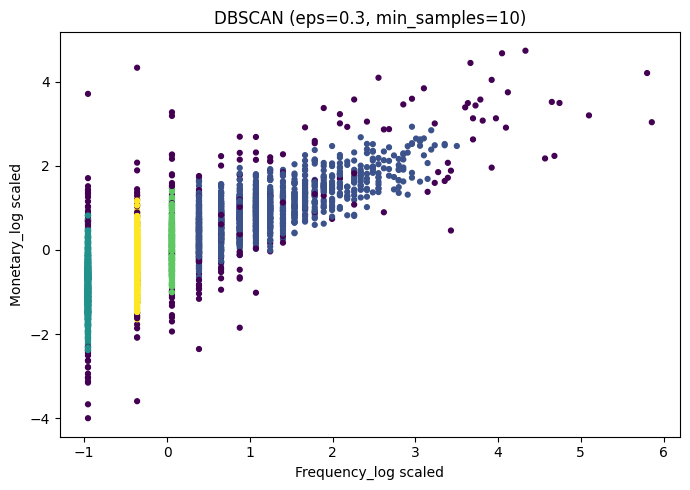

Cluster selain noise: 4
Persentase noise: 6.52 %


In [34]:
# Pilih eps untuk inspeksi; ganti berdasarkan tabel metrik dan tujuan
chosen_eps = 0.3
dbscan_model = dbscan_models[chosen_eps]
labels_db = dbscan_model.labels_

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 1], X_scaled[:, 2], c=labels_db, s=12)
plt.title(f"DBSCAN (eps={chosen_eps}, min_samples=10)")
plt.xlabel("Frequency_log scaled")
plt.ylabel("Monetary_log scaled")
plt.tight_layout(); plt.show()

print("Cluster selain noise:", len(set(labels_db)) - (1 if -1 in labels_db else 0))
print("Persentase noise:", round((labels_db == -1).mean()*100, 2), "%")


## Tugas

1. Jelaskan pengaruh eps terhadap jumlah cluster dan persentase noise.
Pengaruh nilai eps 0.3 radius yang sempit membuat banyak titik tidak memenuhi syarat padat. Hasilnya 4 cluster dengan noise 6,52% tetapi silhouetta hanya 0,105 dan Davies Bouldin 1,93. Pada Pada eps 0,5, radius melebar dan cluster saling menyatu menjadi 2 cluster dengan noise turun menjadi 1,80%, silhouette 0,330 dan Davies-Bouldin 1,12. Pada eps 0,7 sampai 1,3, seluruh titik padat menyatu menjadi 1 cluster dan noise terus turun (0,58%, 0,21%, hingga 0,07%). Jadi, makin besar eps, jumlah cluster dan persentase noise sama-sama menurun.

2. Mengapa silhouette DBSCAN harus ditafsirkan hati-hati ketika ada noise?
Silhouette DBSCAN dihitung hanya pada titik non-noise, sehingga titik yang dianggap noise (misalnya 6,52% pada eps 0,3) tidak ikut dinilai dan skor tampak lebih baik daripada keadaan sebenarnya. Selain itu, silhouette hanya dapat dihitung jika ada minimal 2 cluster. Pada eps 0,7 sampai 1,3 hanya terbentuk 1 cluster sehingga nilainya NaN. Skor tertinggi (0,330 pada eps 0,5) juga hanya berasal dari 2 cluster, sehingga tidak otomatis berarti segmentasi terbaik. Skor ini tidak dapat dibandingkan langsung dengan K-Means yang menilai seluruh titik.

3. Bandingkan DBSCAN dengan K-Means: asumsi cluster seperti apa yang ditangani masing-masing?
K-Means mengasumsikan cluster berbentuk bulat dan berukuran relatif seimbang di sekitar centroid, jumlah cluster (k) harus ditentukan di awal, dan setiap titik pasti masuk ke satu cluster. DBSCAN mengasumsikan cluster sebagai wilayah padat yang dapat berbentuk bebas, tidak memerlukan jumlah cluster di awal, dan dapat menandai titik jarang sebagai noise (-1). Pada data RFM ini, titik tersebar menerus tanpa celah yang jelas antarkelompok (terlihat pada scatter plot), sehingga DBSCAN cenderung menyatukannya menjadi sedikit cluster besar, sedangkan K-Means tetap dapat membaginya sesuai k yang dipilih.

4. Apakah noise selalu berarti data salah? Jelaskan.
Tidak. Noise hanya berarti titik tersebut berada di area yang tidak cukup padat menurut eps dan min_samples, bukan otomatis kesalahan data. Pada scatter plot, titik noise (ungu) banyak berada di area Frequency dan Monetary yang tinggi, yang kemungkinan adalah pelanggan bernilai sangat tinggi atau pembeli grosir yang valid dan justru penting bagi bisnis. Karena itu, noise perlu diperiksa dulu sebelum dibuang atau diabaikan.

## Praktikum 12 Evaluation Membandingkan model

## Kode tabel evaluasi

In [35]:
# Contoh tabel perbandingan hasil K-Means dan Hierarchical
comparison = []

# K-Means: gunakan model yang dipilih pada Praktikum 8
labels = kmeans_model.labels_
comparison.append({
    "algorithm": "K-Means",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Hierarchical: contoh gunakan jumlah cluster terbaik sementara berdasarkan silhouette
best_hier_k = int(metrics_hier.loc[metrics_hier["silhouette"].idxmax(), "k"])
hier_model = hier_models[best_hier_k]
labels = hier_model.labels_
comparison.append({
    "algorithm": "Hierarchical-Ward",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Tambahkan K-Medoids bila instalasi berhasil dan DBSCAN sesuai hasil
comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("silhouette", ascending=False))


,algorithm,n_clusters,silhouette,davies_bouldin,noise_pct
0,K-Means,3,0.415654,0.824915,0.0
1,Hierarchical-Ward,2,0.382603,0.956354,0.0


## Membangun tabel profil cluster

In [36]:
# Contoh profil K-Means pada satu tabel RFM
rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    recency_mean=("Recency", "mean"),
    frequency_mean=("Frequency", "mean"),
    monetary_mean=("Monetary", "mean")
).round(2)
rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)
display(rfm_profile)


,jumlah_pelanggan,recency_median,frequency_median,monetary_median,recency_mean,frequency_mean,monetary_mean,persen_pelanggan
KMeans_Cluster,,,,,,,,
0,2038,46.0,2.0,508.80,55.31,2.05,612.67,46.98
1,980,253.0,1.0,290.46,255.70,1.39,397.03,22.59
2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,30.43


## Panduan memilih tabel

- Periksa metrik internal, tetapi jangan memilih model hanya berdasarkan skor tertinggi.
- Periksa ukuran tiap cluster: apakah ada cluster sangat kecil yang perlu diselidiki?
- Periksa apakah median RFM membedakan segmen secara masuk akal.
- Periksa apakah segmen dapat diterjemahkan menjadi tindakan bisnis yang berbeda.
- Catat trade-off: kemudahan penjelasan, kebutuhan parameter, waktu komputasi, dan sensitivitas terhadap outlier.


## Tugas

Buat tabel perbandingan semua algoritma yang berhasil dijalankan. Jika suatu algoritma gagal karena kompatibilitas paket atau keterbatasan komputasi, laporkan penyebab dan gunakan hasil eksperimen sampel sebagai pembanding yang diberi label jelas.

In [37]:
import numpy as np
import pandas as pd
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

comparison = []

def tambah(nama, X, labels, catatan, noise_pct=0.0):
    comparison.append({
        "algorithm": nama,
        "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "noise_pct": noise_pct,
        "catatan": catatan
    })

# 1. K-Means (k terpilih di Praktikum 8)
tambah(f"K-Means (k={best_k})", X_scaled, kmeans_model.labels_, "Seluruh data")

# 2. K-Means k=2 sebagai pembanding adil terhadap Hierarchical (k=2)
tambah("K-Means (k=2)", X_scaled, models_kmeans[2].labels_, "Seluruh data, k disamakan dengan Hierarchical")

# 3. Hierarchical-Ward
best_hier_k = int(metrics_hier.loc[metrics_hier["silhouette"].idxmax(), "k"])
hier_model = hier_models[best_hier_k]
tambah("Hierarchical-Ward", X_scaled, hier_model.labels_, "Seluruh data")

# 4. Hierarchical-Complete
best_hier_comp_k = int(metrics_hier_complete.loc[metrics_hier_complete["silhouette"].idxmax(), "k"])
hier_comp_model = hier_models_complete[best_hier_comp_k]
tambah("Hierarchical-Complete", X_scaled, hier_comp_model.labels_, "Seluruh data")

# Cek: apakah Ward dan Complete benar-benar berbeda?
print("Linkage Ward    :", hier_model.linkage)
print("Linkage Complete:", hier_comp_model.linkage)
print("ARI Ward vs Complete:", adjusted_rand_score(hier_model.labels_, hier_comp_model.labels_))

# 5. DBSCAN (eps=0.3), metrik hanya pada titik non-noise
chosen_eps = 0.3
labels_db = dbscan_models[chosen_eps].labels_
non_noise = labels_db != -1
n_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
if n_db >= 2:
    tambah(f"DBSCAN (eps={chosen_eps})", X_scaled[non_noise], labels_db[non_noise],
           "Metrik hanya pada titik non-noise",
           noise_pct=round((labels_db == -1).mean() * 100, 2))
    comparison[-1]["n_clusters"] = n_db

# 6. K-Medoids: seluruh data jika berhasil, jika tidak gunakan hasil sampel
try:
    best_kmed_k = int(metrics_kmedoids.loc[metrics_kmedoids["silhouette"].idxmax(), "k"])
    tambah(f"K-Medoids (k={best_kmed_k})", X_scaled, kmedoids_models[best_kmed_k].labels_, "Seluruh data")
except NameError:
    try:
        # Cadangan: sampel (sesuai Praktikum 9). Sesuaikan nama variabel jika berbeda.
        from sklearn_extra.cluster import KMedoids
        kmed_s = KMedoids(n_clusters=best_k, random_state=42, metric="euclidean",
                          method="alternate", init="k-medoids++")
        lab_s = kmed_s.fit_predict(X_sample_scaled)
        tambah(f"K-Medoids (k={best_k}, sampel)", X_sample_scaled, lab_s,
               f"Sampel {len(X_sample_scaled)} pelanggan, tidak sebanding langsung")
    except Exception as e:
        print("K-Medoids gagal dijalankan:", e)

comparison_df = pd.DataFrame(comparison).round(4)
display(comparison_df.sort_values("silhouette", ascending=False))

Linkage Ward    : ward
Linkage Complete: complete
ARI Ward vs Complete: 0.06901753724884573


,algorithm,n_clusters,silhouette,davies_bouldin,noise_pct,catatan
0,K-Means (k=3),3,0.4157,0.8249,0.00,Seluruh data
5,K-Medoids (k=3),3,0.4139,0.8256,0.00,Seluruh data
1,K-Means (k=2),2,0.4063,0.9153,0.00,"Seluruh data, k disamakan dengan Hierarchical"
3,Hierarchical-Complete,2,0.4030,0.6870,0.00,Seluruh data
2,Hierarchical-Ward,2,0.3826,0.9564,0.00,Seluruh data
4,DBSCAN (eps=0.3),4,0.1055,1.9301,6.52,Metrik hanya pada titik non-noise


## Praktikum 13 Evaluation Iteratif dan Profil Cluster

## Tujuan

- Menerjemahkan angka cluster menjadi karakteristik pelanggan.
- Menilai apakah perlu kembali ke Data Preparation atau Modeling.


## Interpretasi

In [38]:
# Kolom profil dihitung dari data; teks interpretasi diisi manual dari hasil profil
prof = rfm.groupby("KMeans_Cluster").agg(
    jumlah=("Recency", "size"),
    r_med=("Recency", "median"),
    f_med=("Frequency", "median"),
    m_med=("Monetary", "median"),
    m_sum=("Monetary", "sum")
)
prof["persen_pelanggan"] = (prof["jumlah"] / prof["jumlah"].sum() * 100).round(2)
prof["persen_pendapatan"] = (prof["m_sum"] / prof["m_sum"].sum() * 100).round(2)

# Interpretasi per cluster (sesuaikan nomor cluster jika hasil notebook-mu berbeda)
interpretasi = {
    2: ("Pelanggan aktif dan bernilai tinggi",
        "Program loyalitas, penawaran eksklusif, prioritas stok produk favorit",
        "Rata-rata Monetary jauh di atas median; ada pelanggan sangat besar (kemungkinan grosir)"),
    0: ("Pelanggan cukup aktif dengan belanja menengah",
        "Rekomendasi produk dan promosi pembelian ulang",
        "Sebagian mungkin pelanggan baru yang belum sempat membeli ulang"),
    1: ("Pelanggan lama tidak aktif",
        "Kampanye reaktivasi terukur",
        "Periksa pelanggan musiman karena data hanya satu tahun"),
}

baris = []
for c in [2, 0, 1]:  # urutan tampil: dari paling bernilai ke paling rendah
    r = prof.loc[c]
    baris.append({
        "Cluster": f"Cluster {c} ({int(r['jumlah']):,} pelanggan, {r['persen_pelanggan']}%)",
        "Profil RFM": (f"Recency median {r['r_med']:.0f} hari; "
                       f"Frequency median {r['f_med']:.0f}; "
                       f"Monetary median {r['m_med']:,.2f}"),
        "Kontribusi pendapatan (%)": r["persen_pendapatan"],
        "Interpretasi sementara": interpretasi[c][0],
        "Tindakan yang mungkin": interpretasi[c][1],
        "Risiko/validasi": interpretasi[c][2],
    })

tabel_interpretasi = pd.DataFrame(baris)
pd.set_option("display.max_colwidth", None)
display(tabel_interpretasi)

,Cluster,Profil RFM,Kontribusi pendapatan (%),Interpretasi sementara,Tindakan yang mungkin,Risiko/validasi
0,"Cluster 2 (1,320 pelanggan, 30.43%)","Recency median 18 hari; Frequency median 7; Monetary median 2,570.49",81.57,Pelanggan aktif dan bernilai tinggi,"Program loyalitas, penawaran eksklusif, prioritas stok produk favorit",Rata-rata Monetary jauh di atas median; ada pelanggan sangat besar (kemungkinan grosir)
1,"Cluster 0 (2,038 pelanggan, 46.98%)",Recency median 46 hari; Frequency median 2; Monetary median 508.80,14.05,Pelanggan cukup aktif dengan belanja menengah,Rekomendasi produk dan promosi pembelian ulang,Sebagian mungkin pelanggan baru yang belum sempat membeli ulang
2,"Cluster 1 (980 pelanggan, 22.59%)",Recency median 253 hari; Frequency median 1; Monetary median 290.46,4.38,Pelanggan lama tidak aktif,Kampanye reaktivasi terukur,Periksa pelanggan musiman karena data hanya satu tahun


## Tugas

Tulis memo evaluasi 1–2 halaman: model yang direkomendasikan, bukti teknis, profil cluster, rekomendasi, keterbatasan, dan eksperimen lanjutan.

1. **Model yang direkomendasikan:**
K-Means dengan 3 cluster fitur Recency, Frequency_log, Monetary_log yang distandarisasi.

2. **Bukti Teknis:**
K-Means memiliki silhouette tertinggi (0,416) dan Davies-Bouldin 0,825. Hierarchical (Ward dan Complete) menghasilkan 2 cluster dengan silhouette 0,403 dan Davies-Bouldin 0,687, sehingga skor kedua model berdekatan dan metrik tidak sepakat soal pemenangnya. DBSCAN (eps 0,3) paling lemah, dengan silhouette 0,105, Davies-Bouldin 1,93, dan noise 6,52%. Pada eps 0,7 sampai 1,3, DBSCAN hanya membentuk satu cluster sehingga tidak berguna untuk segmentasi. K-Means 3 cluster dipilih bukan hanya karena skor, tetapi karena menghasilkan tiga segmen yang berbeda jelas dan berukuran seimbang (23% sampai 47%), sedangkan k = 2 hanya memisahkan dua kelompok kasar.

3. **Profil Cluster:**
Cluster 2 adalah pelanggan aktif bernilai tinggi, cluster 0 pelanggan aktif menengah, dan cluster 1 pelanggan lama tidak aktif (lihat tabel). Dari perkiraan rata-rata Monetary dikali jumlah pelanggan, cluster 2 menyumbang sekitar 81,6% pendapatan, cluster 0 sekitar 14,0%, dan cluster 1 sekitar 4,4%. Pendapatan toko sangat bergantung pada sepertiga pelanggan.

4. **Rekomendasi:**
- Cluster 2: Pertahankan lewat program loyalitas dan layanan eksklusif.
- Cluster 0: dorongan pembelian uang lewat rekomendasi produk dan promosi.
- Cluster 1: Jalankan kampanye reaktivitas dengan anggaran terukur, karena nilainnya paling kecil.

5. **Keterbatasan:**
- Data hanya mencakup satu tahun (1 Desember 2010 - 9 Desember 2011), sehingga pelanggan musiman bisa salah dikelompokkan.
- Baris tanpa CustomerId (24,93%) tidak tercakup, jadi segmentasi hanya mewakili pelanggan teridentifikasi.
- Monetary adalah penjualan kotor karena retur dan pembatalan tidak direkonsiliasi.
- Metrik DBSCAN dihitung tanpa titik noise sehingga tidak sebanding langsung dengan algoritma lain.
- Label segmen bersifat sementara dan bergantung pada fitur, scaling, serta seed yang dipakai.

6. **Eksperimen lanjutan:**
- Ward dan Complete: hasil keduanya identik sampai enam desimal. Pastikan dulu pengecekan linkage (kode ARI) sudah dijalankan, supaya kamu tidak melaporkan perbandingan yang keliru.
- K-Medoids: belum tampak di comparison_df. Kalau sudah dijalankan, tambahkan satu kalimat hasilnya di bukti teknis. Kalau gagal, tulis penyebabnya di keterbatasan.
- Persentase pendapatan adalah perkiraan. Kalau mau angka pasti, hitung rfm.groupby("KMeans_Cluster")["Monetary"].sum() lalu bagi dengan totalnya.
- Label (“aktif bernilai tinggi” dan seterusnya) kuberi berdasarkan profil aktualmu, bukan salinan label contoh modul, sesuai pesan dosen.



## Praktikum 14 Deployment Komunikasi Hasil

## Tujuan

- Menyusun hasil clustering menjadi laporan yang dapat dipahami pengambil keputusan.
- Membedakan hasil analisis, interpretasi, dan rekomendasi.


## Struktur Laporan Akhir

15. Ringkasan eksekutif (maksimal satu halaman).
16. Business Understanding: masalah, tujuan, pertanyaan analitik, kriteria keberhasilan.
17. Data Understanding: sumber, kamus data, kualitas data, EDA dan temuan.
18. Data Preparation: aturan cleaning, agregasi pelanggan, definisi RFM, transformasi dan scaling.
19. Modeling: algoritma, parameter, alasan pemilihan, lingkungan eksperimen.
20. Evaluation: metrik, jumlah/ukuran cluster, profil RFM, perbandingan model.
21. Deployment: rekomendasi tindakan untuk setiap segmen, indikator pemantauan, dan risiko.
22. Reproducibility: kode, versi paket, seed, tanggal acuan, dan keputusan preprocessing.


15. Toko online memiliki cadangan transaksi historis tetapi belum memiliki pengelompokan pelanggan berdasarkan perilaku belanja. Analisis ini membentuk segmen pelanggan dan data Online Retail (UCI) periode 1 Desember 2010 sampai 9 Desember 2010 menggunakan fitur Recency, Frequency dan Monetry (RFM). Setelah pembersihan data, tersisa 4.338 pelanggan. Model yang direkomendasikan adalah K-Means dengan 3 cluster (silhouette 0,416; Davies-Bouldin 0,825) yang menghasilkan tiga segmen: pelanggan aktif bernilai tinggi (30,43%), pelanggan aktif menengah (46,98%), dan pelanggan lama tidak aktif (22,59%). Segmen bernilai tinggi menyumbang sebagian besar pendapatan (perkiraan sekitar 82%), sehingga mempertahankan segmen ini adalah prioritas. Rekomendasi: program loyalitas untuk segmen bernilai tinggi, promosi pembelian ulang untuk segmen menengah, dan kampanye reaktivasi terukur untuk segmen tidak aktif. Hasil bersifat awal karena data hanya mencakup satu tahun dan perlu divalidasi sebelum dipakai untuk keputusan luas.

16. **Masalah Bisnis:** tim pemasaran belum dapat memahami perbedaan pola pembelian pelanggan karena belu ada pengelompokkan berdasarkan perilaku belanja, sehingga komunikasi, program loyalitas, dan promosi belum tepat sasaran. Pengguna hasil adalah manajer pemasaran di dukung oleh tim CRM. Tujuan analitik adalah membentuk kelompok pelanggan berdasarkan perilaku transaksi, dan unit analisis berupa pelanggan.

Pertanyaan analitik:
(1) apakah ada kelompok pelangga dengan frekuensi dan nilai belanja berbeda
(2) Kelompok mana yang lama tidak berbelanja dan berpotensi berhenti membeli
(3) Kelompok mana yang bernilai tinggi dan layak mendapat program loyalitas.

Kriteria keberhasilan: Secara teknis, cluster dapat dievaluasi dengan metrik internal dan tidak didominasi anomali. Secara bisnis, setiap cluster memiliki profil yang dapat dijelaskan dan ditindaklanjuti.

17. sumber Online retail, UCI Machone Learning Repository (diunduh 30 Oktober 2026). Data berisi 541.909 baris dan 8 kolom (InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitePrice, CustomerID, Country), dengan mewakili satu item dalam invoice.

Kualitas data: CustomerID kosong 135.080 baris (24,93%), Description kosong 1.454 baris (0,27%), duplikat identik 5.268 baris (0,97%), invoice berawalan C 9.288 baris (1,71%), Quantity <=0 sebanyak 10.624 baris (1,96%), dan UnitPrice <=0 sebanyak 2.517 baris (0,46%). Kategori ini dapat tumpang tindih. Quantity dan UnitPrice sangat menceng (median 3 dan 2,08, maksimum 80.995 dan 38.970).

Temuan EDA: Nilai transaksi stabil sekitar 0,45 sampai 0,7 juta per bulan sampai Agustus 2011, lalu memuncak sekitar 1,16 juta pada November 2011 (penurunan Desember karena data hanya sampai 9 Desember). United Kingdom mendominasi nilai transaksi (sekitar 7,3 juta, jauh di atas negara lain). Auantity berkorelasi kuat dengan LineValue (0,91), sedangkan UnitePrice hampir tidak berkorelasi dengan Quantity.

18. Aturan cleaning baseline: hapus duplikat identik, CustomerID kosong, InvoiceDate kosong, invoice pembatalan (awalan C), serta Quantity dan UnitPrice yang tidak positif. Baris berkurang dari 541.909 menjadi 392.692 (149.217 baris dikeluarkan, 27,54%), dan tersisa 4.338 pelanggan. Outlier tidak dihapus.

Agregasi: Recency adalah jumlah hari dari transaksi terakhir ke tanggal acuan 10 Desember 2011. Frequency adalah jumlah InvoiceNo unik. Monetary adalah jumlah LineValue (Quantity × UnitPrice). Tabel RFM berukuran 4.338 baris x 3 kolom.

Transformasi: Frequency dan Monetary menceng kuat ke kanan sehingga ditransformasi log1p (Monetary menjadi mendekati lonceng simetris, Frequency lebih terbaca tetapi masih agak menceng). Recency dipertahankan pada skala asli. Fitur model adalah Recency, Frequency_log, dan Monetary_log, lalu distandardisasi dengan StandardScaler. CustomerID tidak dimasukkan sebagai fitur.

19. Algoritma yang dicoba: K-Means (k = 2 sampai 7), K-Medoids (k = 2 sampai 7, dijalankan pada seluruh data dengan scikit-learn-extra, metrik euclidean, metode alternate, inisialisasi k-medoids++), Hierarchical Clustering (Ward dan Complete), dan DBSCAN (eps 0,3; 0,5; 0,7; 1,0; 1,3 dengan min_samples 10). Semua algoritma memakai fitur dan scaling yang sama agar perbandingan adil. Seed: random_state = 42.

Hasil K-Medoids: silhouette tertinggi pada k = 3 (0,414; Davies-Bouldin 0,826), disusul k = 2 (0,395; 0,915). Skor menurun pada k yang lebih besar (k = 6 hanya 0,291). Hasil ini hampir sama dengan K-Means k = 3 (0,416; 0,825), sehingga K-Medoids tidak memberi keunggulan nyata pada data ini.

Alasan pemilihan: K-Means dipilih sebagai model utama karena silhouette tertinggi walau selisihnya kecil, lebih cepat dihitung, dan lebih mudah dijelaskan. K-Medoids berfungsi sebagai pembanding yang lebih tahan terhadap outlier.

In [39]:
import pandas as pd

# 1. Tabel Perbandingan Model Clustering
data_model = {
    "Algoritma": [
        "K-Means (Model Terpilih)",
        "Hierarchical-Ward",
        "Hierarchical-Complete",
        "K-Medoids",
        "DBSCAN (eps=0.3)"
    ],
    "Jumlah Cluster (k)": [3, 2, 2, 3, 4],
    "Silhouette Score": [0.4157, 0.4030, 0.4030, 0.4139, 0.1055],
    "Davies–Bouldin Index": [0.8249, 0.6870, 0.6870, 0.8256, 1.9301],
    "Persentase Noise (%)": ["0.0%", "0.0%", "0.0%", "0.0%", "6.52%"],
    "Catatan & Evaluasi": [
        "Pemisahan paling seimbang & mencakup 100% populasi.",
        "DB index paling rendah, tetapi k=2 terlalu umum.",
        "Performa mirip Ward pada k=2.",
        "Hasil mirip K-Means, namun komputasi lebih berat.",
        "Metrik hanya dihitung pada data non-noise."
    ]
}

df_model = pd.DataFrame(data_model)

# 2. Tabel Ukuran Cluster & Profil RFM (K-Means k=3)
data_profil = {
    "Cluster": [2, 0, 1],
    "Nama Segmen": [
        "Aktif & Bernilai Tinggi",
        "Aktif Belanja Menengah",
        "Lama Tidak Aktif"
    ],
    "Jumlah Pelanggan": [1320, 2038, 980],
    "Persentase Pelanggan": ["30.43%", "46.98%", "22.59%"],
    "Recency Median": ["18 hari", "46 hari", "253 hari"],
    "Frequency Median": ["7 kali", "2 kali", "1 kali"],
    "Monetary Median": ["£2,570.50", "£508.80", "£290.46"],
    "Kontribusi Pendapatan": ["81.57%", "14.05%", "4.38%"]
}

df_profil = pd.DataFrame(data_profil)

# Menampilkan kedua tabel di Colab
print("--- TABEL PERBANDINGAN MODEL CLUSTERING ---")
display(df_model)

print("\n--- TABEL UKURAN CLUSTER & PROFIL RFM (K-MEANS k=3) ---")
display(df_profil)

--- TABEL PERBANDINGAN MODEL CLUSTERING ---


,Algoritma,Jumlah Cluster (k),Silhouette Score,Davies–Bouldin Index,Persentase Noise (%),Catatan & Evaluasi
0,K-Means (Model Terpilih),3,0.4157,0.8249,0.0%,Pemisahan paling seimbang & mencakup 100% populasi.
1,Hierarchical-Ward,2,0.4030,0.6870,0.0%,"DB index paling rendah, tetapi k=2 terlalu umum."
2,Hierarchical-Complete,2,0.4030,0.6870,0.0%,Performa mirip Ward pada k=2.
3,K-Medoids,3,0.4139,0.8256,0.0%,"Hasil mirip K-Means, namun komputasi lebih berat."
4,DBSCAN (eps=0.3),4,0.1055,1.9301,6.52%,Metrik hanya dihitung pada data non-noise.



--- TABEL UKURAN CLUSTER & PROFIL RFM (K-MEANS k=3) ---


,Cluster,Nama Segmen,Jumlah Pelanggan,Persentase Pelanggan,Recency Median,Frequency Median,Monetary Median,Kontribusi Pendapatan
0,2,Aktif & Bernilai Tinggi,1320,30.43%,18 hari,7 kali,"£2,570.50",81.57%
1,0,Aktif Belanja Menengah,2038,46.98%,46 hari,2 kali,£508.80,14.05%
2,1,Lama Tidak Aktif,980,22.59%,253 hari,1 kali,£290.46,4.38%


20. Alasan Pemilihan Model: K-Means (k=3) dipilih sebagai model terbaik karena menghasilkan Silhouette Score tertinggi (0.4157) untuk 3 cluster dan mengelompokkan seluruh data tanpa ada pelanggan yang terbuang sebagai noise.

21. Rekomendasi tindakan:
- Cluster 2 (aktif bernilai tinggi): program loyalitas, penawaran eksklusif, dan prioritas stok produk favorit.
- Cluster 0 (aktif menengah): rekomendasi produk dan promosi pembelian ulang untuk menaikkan frekuensi.
- Cluster 1 (lama tidak aktif): kampanye reaktivasi dengan anggaran terukur.

Indikator pemantauan: proporsi pelanggan tiap segmen, perpindahan pelanggan antarsegmen, tingkat pembelian ulang segmen 0 dan 1, serta konversi dan pendapatan per segmen setelah kampanye.

Risiko: data historis tidak selalu mewakili perilaku masa depan, pelanggan musiman dapat salah dikelompokkan karena data hanya satu tahun, pelanggan tanpa CustomerID (24,93%) tidak tercakup, dan Monetary adalah penjualan kotor karena retur dan pembatalan tidak direkonsiliasi. Segmen bernilai tinggi juga memuat pelanggan ekstrem (rata-rata Monetary 5.492,04 jauh di atas median 2.570,50) yang kemungkinan pembeli grosir dan perlu perlakuan terpisah.

Privasi dan penggunaan data: data pelanggan hanya dipakai untuk analisis perilaku belanja, hasil segmentasi tidak dipakai untuk keputusan sensitif atau otomatis tanpa validasi bisnis, dan lisensi serta ketentuan sumber data diperhatikan sebelum hasil dipublikasikan.

Pembaruan: segmentasi dihitung ulang secara berkala dengan data baru, lalu profil median dan proporsi segmen dibandingkan dengan versi sebelumnya.

In [40]:
import pandas as pd
import numpy as np
import sklearn
import sklearn_extra

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scikit-learn-extra:", sklearn_extra.__version__)

pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
scikit-learn-extra: 0.3.0


22. Dataset: Online Retail, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/352/online+retail), file Online Retail.xlsx, diunduh 31 Oktober 2026..
Periode data: 1 Desember 2010 sampai 9 Desember 2011. Tanggal acuan Recency: 10 Desember 2011.
Seed: random_state = 42 pada semua model dan pengambilan sampel.
Versi paket: Python 3.10, pandas 2.2.3, numpy 2.1.3, scikit-learn 1.6.1, scikit-learn-extra 0.3.0.

Keputusan preprocessing:
1. Hapus duplikat identik, CustomerID kosong, InvoiceDate kosong, invoice berawalan C, serta Quantity dan UnitPrice <= 0. Baris berkurang dari 541.909 menjadi 392.692 dan tersisa 4.338 pelanggan.
2. Agregasi per pelanggan menjadi Recency, Frequency (invoice unik), dan Monetary (jumlah Quantity x UnitPrice).
3. Transformasi log1p pada Frequency dan Monetary, Recency tetap skala asli.
4. StandardScaler pada Recency, Frequency_log, dan Monetary_log.
5. CustomerID tidak dimasukkan sebagai fitur.
6. Label cluster dipetakan kembali ke tabel RFM asli untuk interpretasi.

Parameter model: K-Means dan K-Medoids k = 2 sampai 7 (K-Means n_init = 10, K-Medoids metrik euclidean, metode alternate, inisialisasi k-medoids++), Hierarchical dengan linkage Ward dan Complete, DBSCAN eps 0,3 sampai 1,3 dengan min_samples 10.

## Visualisasi Minimum

## - Grafik tren transaksi


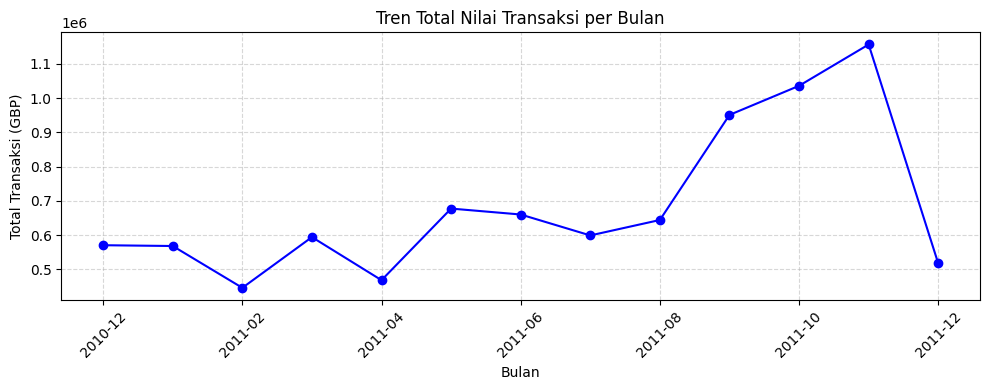

In [41]:
valid_sales = clean.copy()
valid_sales['Month'] = valid_sales['InvoiceDate'].dt.to_period('M').astype(str)
monthly_sales = valid_sales.groupby('Month')['LineValue'].sum()

plt.figure(figsize=(10, 4))
monthly_sales.plot(kind='line', marker='o', color='b')
plt.title('Tren Total Nilai Transaksi per Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Transaksi (GBP)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## - Visualisasi distribusi atau boxplot fitur penting.

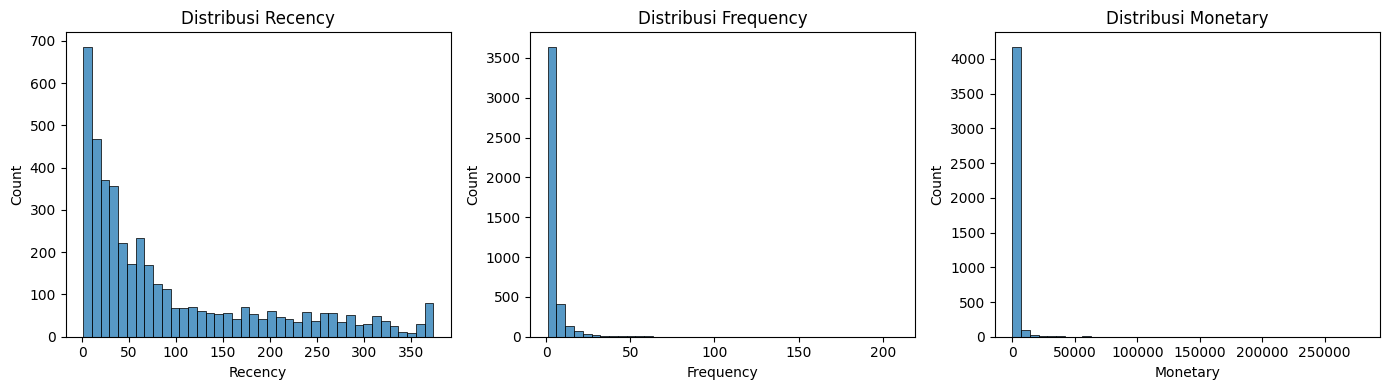

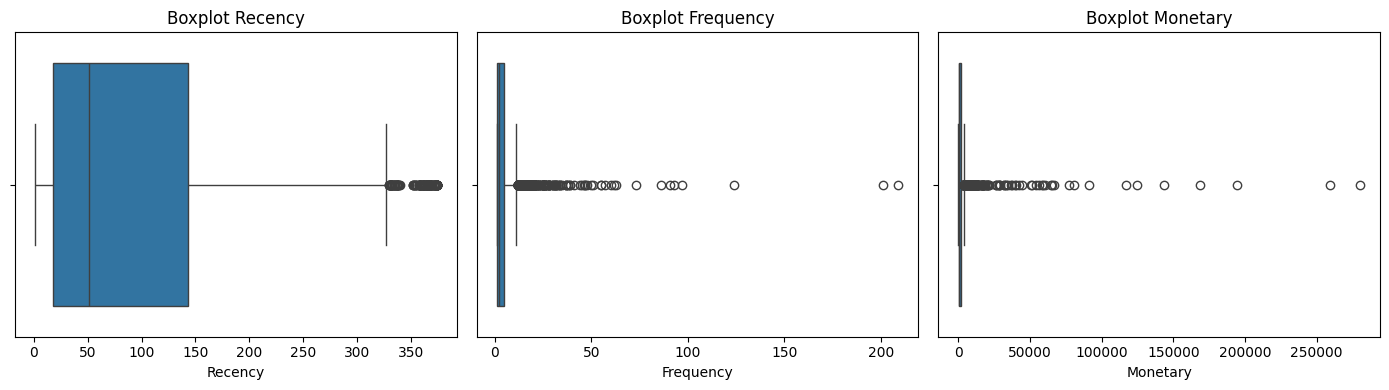

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel(col); ax.set_ylabel("Count")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"Boxplot {col}")
    ax.set_xlabel(col)
plt.tight_layout();
plt.show()

### - Elbow plot untuk K-Means

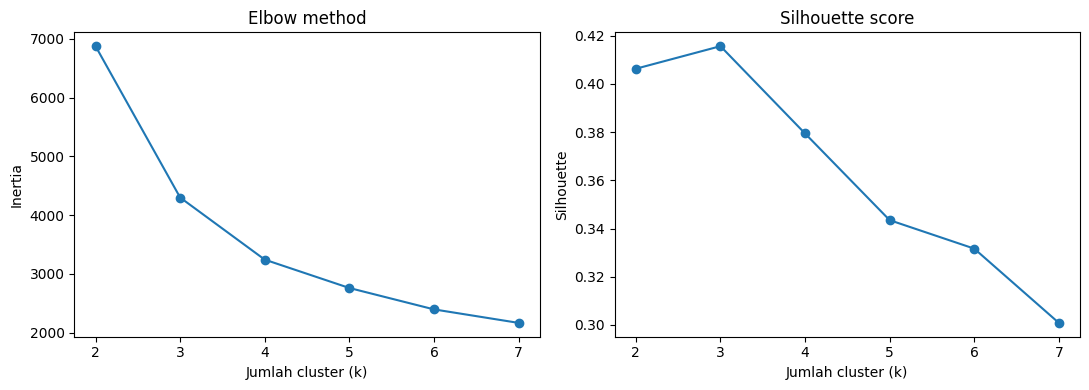

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(metrics_kmeans["k"], metrics_kmeans["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Jumlah cluster (k)"); axes[0].set_ylabel("Inertia")
axes[1].plot(metrics_kmeans["k"], metrics_kmeans["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Jumlah cluster (k)"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

## - Grafik perbandingan Metrik evaluasi antarmodel

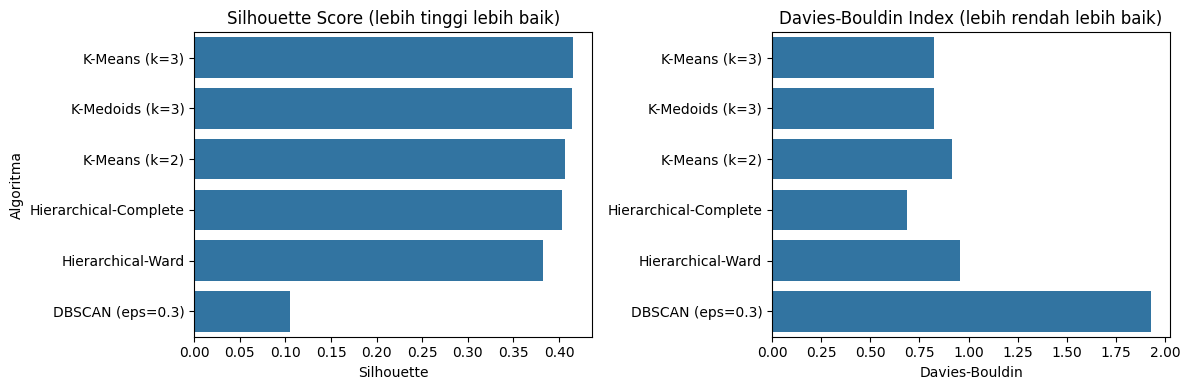

In [44]:
cd = comparison_df.sort_values("silhouette", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=cd, x="silhouette", y="algorithm", ax=axes[0])
axes[0].set_title("Silhouette Score (lebih tinggi lebih baik)")
axes[0].set_xlabel("Silhouette"); axes[0].set_ylabel("Algoritma")

sns.barplot(data=cd, x="davies_bouldin", y="algorithm", ax=axes[1])
axes[1].set_title("Davies-Bouldin Index (lebih rendah lebih baik)")
axes[1].set_xlabel("Davies-Bouldin"); axes[1].set_ylabel("")

plt.tight_layout();
plt.show()

## - Tabel profil cluster berbasis median RFM.

In [45]:
rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    recency_mean=("Recency", "mean"),
    frequency_mean=("Frequency", "mean"),
    monetary_mean=("Monetary", "mean")
).round(2)
rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)
display(rfm_profile)

,jumlah_pelanggan,recency_median,frequency_median,monetary_median,recency_mean,frequency_mean,monetary_mean,persen_pelanggan
KMeans_Cluster,,,,,,,,
0,2038,46.0,2.0,508.80,55.31,2.05,612.67,46.98
1,980,253.0,1.0,290.46,255.70,1.39,397.03,22.59
2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,30.43


## - Scatter plot dua fitur dengan label cluster, disertai keterbatasan visualisasi dua dimensi.

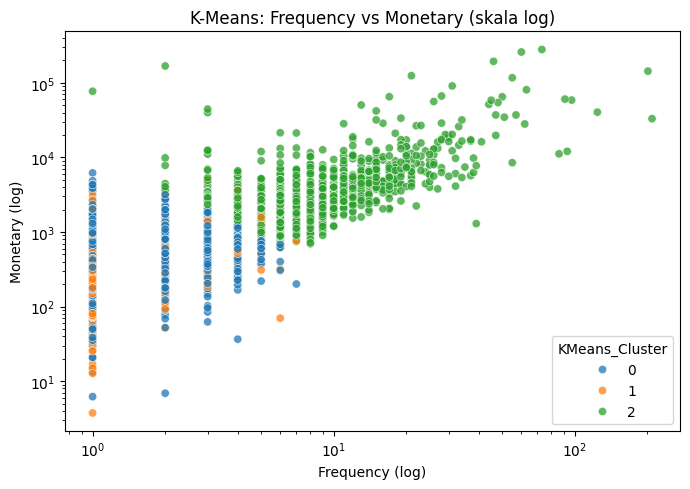

In [46]:
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=rfm, x="Frequency", y="Monetary",
    hue="KMeans_Cluster", palette="tab10", alpha=.75
)
plt.xscale("log"); plt.yscale("log")
plt.title("K-Means: Frequency vs Monetary (skala log)")
plt.xlabel("Frequency (log)"); plt.ylabel("Monetary (log)")
plt.tight_layout(); plt.show()

### Scatter Plot Frequency vs Monetary dengan Label Cluster K-Means

Cluster 2 (hijau) terpisah jelas di area Frequency dan Monetary tinggi, sedangkan cluster 0 (biru) dan cluster 1 (oranye) terkonsentrasi pada Frequency dan Monetary rendah dan saling tumpang tindih. Pola garis vertikal muncul karena Frequency berupa bilangan bulat.

Keterbatasan: plot hanya menampilkan dua dari tiga fitur, sehingga pemisahan berdasarkan Recency tidak terlihat. Karena itu cluster 0 dan cluster 1 tampak menyatu, padahal keduanya berbeda jelas pada Recency (median 46 hari dibanding 253 hari). Pemisahan sebenarnya terjadi pada ruang tiga dimensi (Recency, Frequency_log, Monetary_log) yang telah distandardisasi, sehingga pembacaan visual dua dimensi tidak boleh menjadi satu-satunya dasar penilaian cluster.

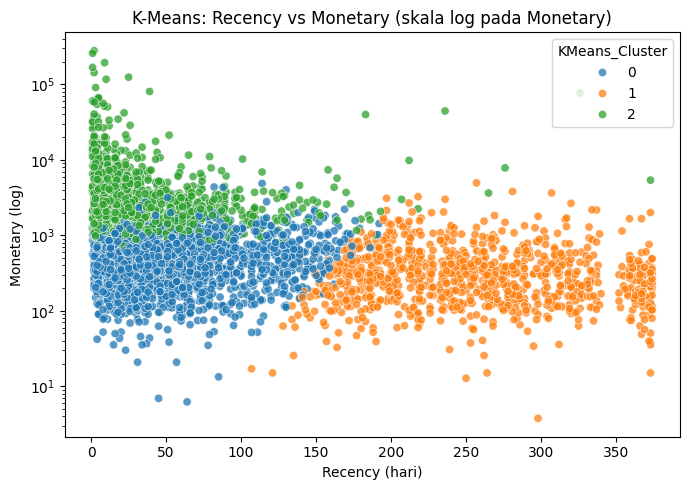

In [47]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary",
                hue="KMeans_Cluster", palette="tab10", alpha=.75)
plt.yscale("log")
plt.title("K-Means: Recency vs Monetary (skala log pada Monetary)")
plt.xlabel("Recency (hari)"); plt.ylabel("Monetary (log)")
plt.tight_layout(); plt.show()

## Prinsip Deployment

Deployment dalam praktikum tidak harus berupa aplikasi produksi. Bentuk awal dapat berupa laporan, notebook yang rapi, dashboard sederhana, atau rekomendasi pemasaran. Jika model akan dipakai secara operasional, perlu prosedur pemantauan perubahan pola pelanggan, pembaruan data, evaluasi berkala, serta peninjauan aspek privasi dan penggunaan data.

## Tahap Deployment 14.1 Menyimpan model clustering menggunakan Joblib




In [48]:
import joblib
import os

os.makedirs("deployment_model", exist_ok=True)

deployment_package = {
    "model": kmeans_model,
    "scaler": scaler,
    "feature_columns": features.columns.tolist(),
    "algorithm": "K-Means",
    "best_k": best_k
}

joblib.dump(
    deployment_package,
    "deployment_model/clustering_deployment.joblib"
)

print("model berhasil disimpan!")
print("Algoritma:", deployment_package["algorithm"])
print("Jumlah cluster:", deployment_package["best_k"])
print("Fitur:", deployment_package["feature_columns"])


model berhasil disimpan!
Algoritma: K-Means
Jumlah cluster: 3
Fitur: ['Recency', 'Frequency_log', 'Monetary_log']


## 14.2 Memuat model yang telah disimpan

In [49]:
# Memuat model dari file Joblib
loaded_package = joblib.load(
    "deployment_model/clustering_deployment.joblib"
)

# Mengambil model dan scaler
loaded_model = loaded_package["model"]
loaded_scaler = loaded_package["scaler"]

# Mengambil informasi fitur
feature_columns = loaded_package["feature_columns"]

print("Model berhasil dimuat!")
print("Algoritma:", loaded_package["algorithm"])
print("Jumlah cluster:", loaded_package["best_k"])
print("Fitur model:", feature_columns)

Model berhasil dimuat!
Algoritma: K-Means
Jumlah cluster: 3
Fitur model: ['Recency', 'Frequency_log', 'Monetary_log']


### Praktikum 13.3 Prediksi cluster pelanggan baru

In [50]:
# ============================================================
# PRAKTIKUM 13.3
# PREDIKSI CLUSTER PELANGGAN BARU
# ============================================================

import pandas as pd
import numpy as np

# Data RFM pelanggan baru (Monetary dalam GBP, sesuai data latih)
data_baru = pd.DataFrame({
    "Recency": [18],
    "Frequency": [7],
    "Monetary": [2570.50]
})

# Melakukan transformasi log sesuai Praktikum 7
data_baru["Frequency_log"] = np.log1p(
    data_baru["Frequency"]
)

data_baru["Monetary_log"] = np.log1p(
    data_baru["Monetary"]
)

# Mengambil fitur sesuai urutan saat training
data_baru_features = data_baru[feature_columns]

# Melakukan scaling menggunakan scaler lama
data_baru_scaled = loaded_scaler.transform(
    data_baru_features
)

# Melakukan prediksi cluster
hasil_prediksi = loaded_model.predict(
    data_baru_scaled
)

# Menambahkan hasil prediksi dan nama segmen (sesuai profil RFM K-Means k=3)
nama_segmen = {
    2: "Aktif & Bernilai Tinggi",
    0: "Aktif Belanja Menengah",
    1: "Lama Tidak Aktif"
}

data_baru["Cluster"] = hasil_prediksi
data_baru["Nama Segmen"] = data_baru["Cluster"].map(nama_segmen)

print("Data pelanggan baru:")
display(data_baru)

print("Hasil prediksi cluster:")
print("Pelanggan masuk ke Cluster:", hasil_prediksi[0])
print("Segmen:", nama_segmen[hasil_prediksi[0]])

Data pelanggan baru:


,Recency,Frequency,Monetary,Frequency_log,Monetary_log,Cluster,Nama Segmen
0,18,7,2570.5,2.079442,7.852245,2,Aktif & Bernilai Tinggi


Hasil prediksi cluster:
Pelanggan masuk ke Cluster: 2
Segmen: Aktif & Bernilai Tinggi


In [51]:
# ============================================================
# PRAKTIKUM 13.4
# PREDIKSI BEBERAPA PELANGGAN BARU
# ============================================================

# Membuat data beberapa pelanggan baru (Monetary dalam GBP, sesuai data latih)
data_pelanggan = pd.DataFrame({
    "CustomerID": ["C001", "C002", "C003", "C004"],
    "Recency":   [18, 46, 253, 10],
    "Frequency": [7, 2, 1, 15],
    "Monetary":  [2570.50, 508.80, 290.46, 5500.00]
})

# Transformasi logaritmik sesuai Praktikum 7
data_pelanggan["Frequency_log"] = np.log1p(
    data_pelanggan["Frequency"]
)

data_pelanggan["Monetary_log"] = np.log1p(
    data_pelanggan["Monetary"]
)

# Memilih fitur sesuai model
X_pelanggan_baru = data_pelanggan[feature_columns]

# Scaling menggunakan scaler hasil Praktikum 8 (yang disimpan di Joblib)
X_pelanggan_scaled = loaded_scaler.transform(
    X_pelanggan_baru
)

# Prediksi cluster menggunakan model yang telah di-load
data_pelanggan["Cluster"] = loaded_model.predict(
    X_pelanggan_scaled
)

# Menambahkan nama segmen sesuai profil RFM K-Means k=3
data_pelanggan["Nama Segmen"] = data_pelanggan["Cluster"].map(nama_segmen)

# Menampilkan hasil prediksi
display(
    data_pelanggan[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Cluster", "Nama Segmen"]
    ]
)

,CustomerID,Recency,Frequency,Monetary,Cluster,Nama Segmen
0,C001,18,7,2570.50,2,Aktif & Bernilai Tinggi
1,C002,46,2,508.80,0,Aktif Belanja Menengah
2,C003,253,1,290.46,1,Lama Tidak Aktif
3,C004,10,15,5500.00,2,Aktif & Bernilai Tinggi


In [59]:
# ============================================================
# PRAKTIKUM 13.5
# MENGUNDUH FILE MODEL
# ============================================================

from google.colab import files

files.download(
    "deployment_model/clustering_deployment.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [60]:
# Install streamlit dan pyngrok
!pip install streamlit pyngrok --quiet

In [61]:
%%writefile app.py
# ==========================================
# APLIKASI STREAMLIT
# Segmentasi Pelanggan Online Retail
# ==========================================

import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Memuat model dan scaler
package = joblib.load(
    "deployment_model/clustering_deployment.joblib"
)

model = package["model"]
scaler = package["scaler"]
feature_columns = package["feature_columns"]

# Nama segmen dan tindakan sesuai profil RFM K-Means k=3
nama_segmen = {
    2: "Aktif & Bernilai Tinggi",
    0: "Aktif Belanja Menengah",
    1: "Lama Tidak Aktif"
}

tindakan = {
    2: "Program loyalitas, penawaran eksklusif, prioritas stok produk favorit",
    0: "Rekomendasi produk dan promosi pembelian ulang",
    1: "Kampanye reaktivasi dengan anggaran terukur"
}

# Judul aplikasi
st.title("Segmentasi Pelanggan Online Retail")
st.write("Prediksi cluster pelanggan menggunakan K-Means")

# Input data pelanggan
recency = st.number_input(
    "Recency (hari)", min_value=0, value=15
)

frequency = st.number_input(
    "Frequency (transaksi)", min_value=1, value=8
)

monetary = st.number_input(
    "Monetary (GBP)", min_value=0.01, value=2500.0
)

# Tombol prediksi
if st.button("Prediksi Cluster"):

    # Membentuk data pelanggan
    data = pd.DataFrame({
        "Recency": [recency],
        "Frequency_log": [np.log1p(frequency)],
        "Monetary_log": [np.log1p(monetary)]
    })

    # Scaling menggunakan scaler lama
    data_scaled = scaler.transform(
        data[feature_columns]
    )

    # Prediksi cluster
    cluster = int(model.predict(data_scaled)[0])

    # Menampilkan hasil
    st.success(
        f"Pelanggan masuk ke Cluster {cluster}: {nama_segmen[cluster]}"
    )
    st.write("Tindakan yang disarankan:", tindakan[cluster])

Overwriting app.py


In [62]:
!pip install streamlit joblib scikit-learn pandas numpy

In [ ]:
!pip install streamlit joblib scikit-learn pandas numpy

!streamlit run app.py



2026-11-17 05:29:25.187 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.115.164.245:8501



# BAB 3 Template Notebook Praktikum

## Log Keputusan eksperimen

In [57]:
import pandas as pd

log_keputusan = pd.DataFrame([
    {
        "Tanggal/tahap": "EDA",
        "Keputusan": "Memeriksa InvoiceNo berawalan C sebagai pembatalan",
        "Alasan/bukti": "9.288 baris (1,71%); sesuai dokumentasi sumber data (UCI)",
        "Dampak": "Pembatalan dikeluarkan dari agregasi",
        "Perlu diuji lagi?": "Tidak",
    },
    {
        "Tanggal/tahap": "EDA",
        "Keputusan": "CustomerID kosong dikeluarkan dari analisis pelanggan, tetapi tidak dihapus dari seluruh EDA",
        "Alasan/bukti": "135.080 baris (24,93%) tidak dapat diagregasi per pelanggan",
        "Dampak": "Segmentasi hanya mewakili pelanggan yang teridentifikasi",
        "Perlu diuji lagi?": "Ya, apakah pelanggan tanpa ID berperilaku berbeda",
    },
    {
        "Tanggal/tahap": "Preparation",
        "Keputusan": "Cleaning baseline: hapus duplikat, CustomerID kosong, invoice C, serta Quantity dan UnitPrice <= 0",
        "Alasan/bukti": "Baris turun dari 541.909 menjadi 392.692; tersisa 4.338 pelanggan",
        "Dampak": "Monetary menjadi penjualan kotor (retur belum direkonsiliasi)",
        "Perlu diuji lagi?": "Ya, rekonsiliasi retur",
    },
    {
        "Tanggal/tahap": "Preparation",
        "Keputusan": "Menggunakan log1p untuk Frequency dan Monetary; Recency tetap skala asli",
        "Alasan/bukti": "Distribusi menceng kuat ke kanan (Monetary: median 668,57, maksimum 280.206,02)",
        "Dampak": "Mengurangi dominasi pelanggan bernilai sangat besar",
        "Perlu diuji lagi?": "Tidak",
    },
    {
        "Tanggal/tahap": "Preparation",
        "Keputusan": "StandardScaler pada Recency, Frequency_log, Monetary_log; CustomerID tidak dimasukkan sebagai fitur",
        "Alasan/bukti": "Algoritma berbasis jarak peka terhadap skala; CustomerID hanya pengenal",
        "Dampak": "Ketiga fitur memiliki bobot setara dalam perhitungan jarak",
        "Perlu diuji lagi?": "Tidak",
    },
    {
        "Tanggal/tahap": "Modeling",
        "Keputusan": "Mencoba k=2 sampai 7 pada K-Means, K-Medoids, dan Hierarchical",
        "Alasan/bukti": "Eksplorasi jumlah cluster dengan Silhouette dan Davies-Bouldin",
        "Dampak": "Menghasilkan kandidat model dan nilai k",
        "Perlu diuji lagi?": "Ya, coba k=4 untuk memecah cluster bernilai tinggi",
    },
    {
        "Tanggal/tahap": "Modeling",
        "Keputusan": "DBSCAN memakai eps=0,3 dan min_samples=10 untuk inspeksi",
        "Alasan/bukti": "Hanya eps 0,3 yang menghasilkan lebih dari 2 cluster; eps 0,7 sampai 1,3 hanya 1 cluster",
        "Dampak": "4 cluster dengan noise 6,52% dan silhouette rendah (0,105)",
        "Perlu diuji lagi?": "Ya, uji eps dan min_samples lain",
    },
    {
        "Tanggal/tahap": "Evaluation",
        "Keputusan": "Memilih K-Means dengan k=3 sebagai model rekomendasi",
        "Alasan/bukti": "Silhouette tertinggi (0,416) dan menghasilkan 3 segmen yang berbeda jelas serta berukuran seimbang",
        "Dampak": "Profil segmen dapat ditindaklanjuti oleh tim pemasaran",
        "Perlu diuji lagi?": "Ya, uji stabilitas dengan seed berbeda",
    },
])

pd.set_option("display.max_colwidth", None)
display(log_keputusan)

log_keputusan.to_csv("log_keputusan_eksperimen.csv", index=False)

,Tanggal/tahap,Keputusan,Alasan/bukti,Dampak,Perlu diuji lagi?
0,EDA,Memeriksa InvoiceNo berawalan C sebagai pembatalan,"9.288 baris (1,71%); sesuai dokumentasi sumber data (UCI)",Pembatalan dikeluarkan dari agregasi,Tidak
1,EDA,"CustomerID kosong dikeluarkan dari analisis pelanggan, tetapi tidak dihapus dari seluruh EDA","135.080 baris (24,93%) tidak dapat diagregasi per pelanggan",Segmentasi hanya mewakili pelanggan yang teridentifikasi,"Ya, apakah pelanggan tanpa ID berperilaku berbeda"
2,Preparation,"Cleaning baseline: hapus duplikat, CustomerID kosong, invoice C, serta Quantity dan UnitPrice <= 0",Baris turun dari 541.909 menjadi 392.692; tersisa 4.338 pelanggan,Monetary menjadi penjualan kotor (retur belum direkonsiliasi),"Ya, rekonsiliasi retur"
3,Preparation,Menggunakan log1p untuk Frequency dan Monetary; Recency tetap skala asli,"Distribusi menceng kuat ke kanan (Monetary: median 668,57, maksimum 280.206,02)",Mengurangi dominasi pelanggan bernilai sangat besar,Tidak
4,Preparation,"StandardScaler pada Recency, Frequency_log, Monetary_log; CustomerID tidak dimasukkan sebagai fitur",Algoritma berbasis jarak peka terhadap skala; CustomerID hanya pengenal,Ketiga fitur memiliki bobot setara dalam perhitungan jarak,Tidak
5,Modeling,"Mencoba k=2 sampai 7 pada K-Means, K-Medoids, dan Hierarchical",Eksplorasi jumlah cluster dengan Silhouette dan Davies-Bouldin,Menghasilkan kandidat model dan nilai k,"Ya, coba k=4 untuk memecah cluster bernilai tinggi"
6,Modeling,"DBSCAN memakai eps=0,3 dan min_samples=10 untuk inspeksi","Hanya eps 0,3 yang menghasilkan lebih dari 2 cluster; eps 0,7 sampai 1,3 hanya 1 cluster","4 cluster dengan noise 6,52% dan silhouette rendah (0,105)","Ya, uji eps dan min_samples lain"
7,Evaluation,Memilih K-Means dengan k=3 sebagai model rekomendasi,"Silhouette tertinggi (0,416) dan menghasilkan 3 segmen yang berbeda jelas serta berukuran seimbang",Profil segmen dapat ditindaklanjuti oleh tim pemasaran,"Ya, uji stabilitas dengan seed berbeda"


## Kesimpulan

Kesimpulan

Analisis ini menggunakan dataset transaksi Online Retail dari UCI Machine Learning Repository periode 1 Desember 2010 sampai 9 Desember 2011. Setelah proses pembersihan data, tersisa 392.692 baris transaksi bersih dari total 541.909 baris awal, yang kemudian diringkas menjadi fitur perilaku pelanggan RFM (Recency, Frequency, dan Monetary) untuk 4.338 pelanggan unik.Berdasarkan perbandingan beberapa algoritma, model yang direkomendasikan adalah K-Means ($k=3$) karena memberikan keseimbangan terbaik antara metrik matematis dan interpretasi bisnis, menghasilkan skor Silhouette 0,4157 dan Davies–Bouldin Index 0,8249 tanpa ada data yang terbuang sebagai noise (0,0%).

## Jawaban Pertanyaan Analitik

1. Apakah terdapat kelompok pelanggan dengan frekuensi pembelian dan nilai belanja yang berbeda?

Ya. Terbentuk tiga kelompok dengan profil yang terpisah jelas. Cluster 2 (30,43% pelanggan) memiliki median Frequency 7 dan Monetary 2.570,50, cluster 0 (46,98%) memiliki Frequency 2 dan Monetary 508,80, dan cluster 1 (22,59%) memiliki Frequency 1 dan Monetary 290,46. Perbedaan ini konsisten pada ketiga fitur, sehingga segmentasi bermakna dan bukan sekadar hasil pembagian acak.



2.  Kelompok mana yang berisi pelanggan yang lama tidak berbelanja dan berpotensi berhenti membeli?

Cluster 1, dengan median Recency 253 hari, Frequency 1, dan Monetary terendah. Pelanggan ini sudah lama tidak kembali dan hanya membeli sekali, sehingga menjadi sasaran kampanye reaktivasi yang terukur. Nilai kontribusinya relatif kecil, jadi anggaran reaktivasi sebaiknya dibatasi.

3. Kelompok mana yang berisi pelanggan bernilai tinggi dan layak mendapat program loyalitas?

Kelompok tersebut adalah Cluster 2 (Pelanggan Aktif & Bernilai Tinggi), dengan median Recency 18 hari, Frequency 7 kali, dan Monetary £2.570,50. Kontribusinya terhadap pendapatan sangat besar 81,57% dari total pendapatan toko, yang menunjukkan bahwa pendapatan bisnis sangat bergantung pada sepertiga populasi pelanggan ini. Oleh karena itu, kelompok Cluster 2 sangat layak mendapatkan prioritas stok, penawaran eksklusif, serta program loyalitas khusus untuk menjaga retensi mereka.

## Rencana Lanjutan

1. Uji stabilitas K-Means dengan seed berbeda dan coba k = 4 untuk melihat apakah cluster bernilai tinggi dapat dipecah menjadi pelanggan reguler dan grosir.
2. Tambahkan fitur lain (misalnya rata-rata nilai per invoice) dan uji pengaruhnya jika Monetary dikeluarkan.
3. Rekonsiliasi retur dan pembatalan agar Monetary mendekati penjualan bersih.
4. Ulangi analisis dengan periode data yang lebih panjang untuk memvalidasi segmen musiman.
5. Uji hasil pada kampanye kecil per segmen sebelum dipakai secara luas, lalu pantau perpindahan pelanggan antarsegmen secara berkala.

# BAB 4 Rubrik Penilaian

## Pertanyaan Evaluasi Akhir

### 23. Jelaskan perbedaan Business Understanding dan Data Understanding pada proyek ini.




Business understanding fokus pada perumusan masalah bisnis, tujuan analitik, kriteria keberhasilan, serta penetapan pengguna terakhir tanpa menyebutkan algoritma tertentu. Sementara Data understanding berfokus pada pemahaman struktur dataset, arti tiap kolom, rentang waktu, penemuan nilai kosong atau anomali data, serta evaluasi kesiapan data awal untuk menjawab tujuan bisnis tersebut.

### 24. Mengapa EDA harus dilakukan sebelum pembersihan data final?


EDA dilakukan untuk mengenali karakteristik data secara utuh, membedakan anomali dari kejadian bisnis yang valid seperti pembelian grosir, sehingga aturan pemebrsihan data dapat dirancang secara objektif tanpa membuang informasi penting.

### 25. Mengapa transaksi tidak sama dengan pelanggan sebagai unit analisis?


Satu baris transaksi mencatat pembelian item per nota, sedangkan tujuan segmentasi adalah mengelompokkan profil orangnya. Oleh karena itu, data transaksi harus diagregasi terlebih dahulu menjadi satu baris per pelanggan unik (CustomerID).

### 26. Jelaskan definisi Recency, Frequency, dan Monetary serta satu keterbatasan masing-masing.


Recency adalah jarak waktu dari transaksi terakhir; keterbatasannya bisa keliru membaca pelanggan musiman. Frequency adalah jumlah nota belanja; keterbatasannya tidak mencatat jarak waktu antar belanjaan. Monetary adalah total nilai belanja; keterbatasannya bisa keliru jika retur tidak dikurangkan.

### 27. Mengapa scaling penting untuk K-Means dan DBSCAN?

Kedua algoritma bekerja berdasarkan perhitungan jarak Euclidean. Tanpa scaling, fitur dengan nilai nominal sangat besar (seperti Monetary) akan mendominasi dan membiaskan hasil kelompok

### 28. Bandingkan prinsip K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN.

K-Means membagi data berdasarkan jarak rata-rata (centroid), K-Medoids menggunakan titik data nyata (medoid) sehingga lebih tahan outlier, Hierarchical menyusun kelompok secara bertahap lewat pohon (dendrogram), sedangkan DBSCAN mengelompokkan data berdasarkan kerapatan wilayah dan mendeteksi noise.

### 29. Bagaimana Elbow Method dan Silhouette Score digunakan, dan apa keterbatasannya?


Elbow Method melihat titik lengkung penurunan inertia namun bersifat subjektif. Silhouette Score mengukur tingkat kerapatan dan pemisahan matematis, namun tidak menjamin segmen tersebut relevan secara bisnis.

### 30. Apa makna label -1 pada DBSCAN?


Label -1 menandakan bahwa titik data tersebut dikategorikan sebagai noise (pencilan) karena berada di wilayah yang tidak memenuhi syarat kepadatan minimum dalam radius pencarian (eps).

### 31. Mengapa skor evaluasi internal tidak cukup untuk menentukan model terbaik?


Skor evaluasi internal hanya menguji validitas matematis. Model dengan skor tertinggi belum tentu menghasilkan segmen pelanggan yang mudah dipahami atau dapat ditindaklanjuti secara taktis oleh tim pemasaran.

### 32. Berikan contoh rekomendasi berbeda untuk dua cluster berdasarkan profil RFM aktual.


Segmen pelanggan aktif bernilai tinggi diberi program loyalitas eksklusif dan layanan prioritas untuk retensi, sedangkan pelanggan lama yang tidak aktif diberi kampanye reaktivasi terukur atau promosi diskon kembali berbelanja (win-back).

# BAB 5 CATATAN TEKNIS dan BATASAN

- Dataset Online Retail relatif besar untuk praktik pemula. Jika perangkat terbatas, lakukan EDA pada data lengkap bila memori cukup dan gunakan sampel terdokumentasi untuk eksperimen algoritma yang mahal.
- K-Medoids tidak termasuk implementasi inti scikit-learn. Paket scikit-learn-extra dapat memiliki isu kompatibilitas tergantung versi Python/NumPy; siapkan opsi sampel atau demonstrasi alternatif.
- Silhouette Score dan Davies–Bouldin Index mengasumsikan representasi jarak tertentu dan tidak selalu cocok untuk semua bentuk cluster. Pada DBSCAN, evaluasi harus menjelaskan bagaimana noise diperlakukan.
- RFM yang dibentuk dari baseline transaksi positif tidak identik dengan pendapatan akuntansi bersih jika retur/pembatalan tidak direkonsiliasi secara penuh.
Data transaksi historis tidak menjamin perilaku pelanggan masa depan. Jangan membuat klaim kausal atau keputusan sensitif hanya berdasarkan cluster.
- Periksa lisensi, ketentuan sumber, dan praktik privasi sebelum mendistribusikan dataset atau mempublikasikan hasil.


## Referensi dan Sumber Belajar

- UCI Machine Learning Repository. Online Retail Dataset. https://archive.ics.uci.edu/dataset/352/online+retail
- Shearer, C. (2000). The CRISP-DM Model: The New Blueprint for Data Mining. Journal of Data Warehousing, 5(4), 13–22.
- scikit-learn documentation: Clustering. https://scikit-learn.org/stable/modules/clustering.html
- scikit-learn documentation: StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- scikit-learn documentation: silhouette_score. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html
- scikit-learn-extra documentation: KMedoids. https://scikit-learn-extra.readthedocs.io/
